# SDF-GS Refine - Full Pipeline (Run All) - FIX 1

Post-hoc 3D mesh extraction: 3D Gaussian Splatting + neural SDF.
DTU scan105 (teddy bear), paper-spec hyperparameters (10K iters).

**Press Run All and wait.** Each stage caches to `run_artifacts/`;
re-running skips completed stages unless you set `FORCE_STAGE`.

FIX 1 - hardens the notebook that previously produced a flat, featureless
shell instead of a teddy:

- **Surface supervision density**: BATCH raised to the paper spec of **1024**
  cached surface points per step (was 256). With ~176K surface samples spread
  over all DTU cameras, 256 pts/step was only ~5 pts/camera/step - too sparse
  to carve ears/arms/legs. 1024 gives ~20 pts/camera/step.
- **Loss rebalance**: `lambda_normal` 0.05 -> **0.20** (drive the SDF hard onto
  the extracted surface normals to recover concavity/features) and
  `lambda_eikonal` 0.1 -> **0.05** (avoid the degenerate over-smooth field).
- **Dropped the synthetic photometric term**: when no real images exist the
  "photometric target" was a perturbed frozen snapshot that carries almost no
  positional signal and only wastes GPU. It is now omitted (weight 0); the SDF
  is driven by the cached surface samples + eikonal (the core paper
  contribution). Real-image photometric still turns on automatically if real
  observed images are found.
- **Fresh run forced**: FORCE_STAGE["surface_samples"]/["training"]/["mesh"]
  all True on the first run so no stale under-trained checkpoint is reused,
  and a new RUN_HASH gives a clean artifact folder.
- **10,000 iterations**, 1024 pts/step, mesh snapshots every 1000 iters.


## 1. Environment

In [1]:
import os, subprocess, sys, random, json, hashlib, time, gc, shutil, stat
from pathlib import Path

# --- Dependency guard ---
PINNED_NUMPY = "1.26.4"
os.environ["PIP_CONSTRAINT"] = "/tmp/sdf_gs_constraints.txt"
with open(os.environ["PIP_CONSTRAINT"], "w") as fp:
    fp.write(f"numpy=={PINNED_NUMPY}\n")

def _ensure(package, import_name=None):
    try:
        __import__(import_name or package)
    except ImportError:
        subprocess.run([sys.executable, "-m", "pip", "install", "--quiet", package], check=True)

for pkg, imp in [("torch", "torch"), ("kagglehub", "kagglehub"), ("plyfile", "plyfile"),
                 ("trimesh", "trimesh"), ("scipy", "scipy"), ("scikit-image", "skimage"),
                 ("matplotlib", "matplotlib")]:
    _ensure(pkg, imp)

try:
    import numpy as np
    assert np.__version__ == PINNED_NUMPY
except Exception:
    subprocess.run([sys.executable, "-m", "pip", "install", "--no-cache-dir", f"numpy=={PINNED_NUMPY}"], check=True)
    print("NumPy reinstalled. Restart kernel, then Run All again.")

import torch
import trimesh
from plyfile import PlyData

# --- Project root ---
def find_project_root(marker="src/utils.py", start=None, max_depth=3):
    here = Path(start or os.getcwd()).resolve()
    candidates = [here] + list(here.parents)
    for depth in range(1, max_depth + 1):
        candidates.extend(p for p in here.glob("/".join(["*"] * depth)) if p.is_dir())
    for root in (Path("/content"), Path("/kaggle/working"), Path("/notebooks"), Path.home()):
        if root.exists():
            candidates.extend(root.glob("**/SDF-GS-Refine-implementation"))
    seen = set()
    for c in candidates:
        if c not in seen and (c / marker).exists():
            return c
        seen.add(c)
    return None

PROJECT_ROOT = find_project_root()
if PROJECT_ROOT is None:
    raise ModuleNotFoundError("Could not locate src/utils.py. Set PROJECT_ROOT manually.")
sys.path.insert(0, str(PROJECT_ROOT))

from src.utils import set_seed, get_device, log, load_config, ensure_dir
from src import gaussian, camera, transmittance, sdf, losses, mesh as mesh_mod, evaluation, synthetic

SEED = 42
set_seed(SEED)
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
torch.use_deterministic_algorithms(True, warn_only=True)
torch.backends.cudnn.benchmark = False
torch.backends.cudnn.deterministic = True
DEVICE = get_device()
log(f"Project root: {PROJECT_ROOT}")
log(f"seed={SEED} device={DEVICE} torch={torch.__version__} cuda={torch.cuda.is_available()}")

NumPy reinstalled. Restart kernel, then Run All again.
[11:28:11] Project root: /notebooks/Generated/SDF-GS-Refine-implementation
[11:28:11] seed=42 device=cuda torch=2.1.1+cu121 cuda=True


## 2. Configuration

Hyperparameters from paper Bab III / Table 3.3. Overrides applied in
memory only — `configs/config.json` is never modified.

In [2]:
CONFIG_PATH = PROJECT_ROOT / "configs" / "config.json"
log(f"Loading config from: {CONFIG_PATH}")
CFG = load_config(str(CONFIG_PATH))

# --- Paper-spec overrides (in memory only) ---
# The config.json keeps its smoke-test defaults (300 iters, batch 64, grid 96)
# for backward compat. We override here for the full paper-spec run.
CFG["joint_refinement"]["n_iterations_smoke_test"] = 10000
CFG["joint_refinement"]["batch_size_rays_smoke_test"] = 1024   # paper spec (was 256)
CFG["mesh_extraction"]["grid_resolution_smoke_test"] = 160

# --- FIX 1: rebalance loss weights to stop the featureless-shell collapse ---
CFG["joint_refinement"]["lambda_normal"] = 0.20   # was 0.05 -> carve features
CFG["joint_refinement"]["lambda_eikonal"] = 0.05  # was 0.1  -> less over-smoothing

print("=== Configuration (after overrides) ===")
for k in ("sdf_network", "joint_refinement", "transmittance", "mesh_extraction",
          "mesh_postprocess", "evaluation"):
    print(f"\n-- {k} --")
    for kk, vv in CFG[k].items():
        if not kk.startswith("_"):
            print(f"   {kk}: {vv}")


[11:28:11] Loading config from: /notebooks/Generated/SDF-GS-Refine-implementation/configs/config.json
=== Configuration (after overrides) ===

-- sdf_network --
   d_hidden: 256
   n_layers: 8
   activation: softplus
   softplus_beta: 100.0
   radius_init: 1.0

-- joint_refinement --
   lambda_eikonal: 0.05
   lambda_normal: 0.2
   lr_gaussian: 0.0001
   lr_sdf: 0.0005
   n_iterations_paper: 10000
   n_iterations_smoke_test: 10000
   batch_size_rays_paper: 1024
   batch_size_rays_smoke_test: 1024

-- transmittance --
   min_opacity_filter: 0.05
   cull_sigma: 4.0
   max_candidates_per_ray: 4096

-- mesh_extraction --
   grid_resolution_paper: 512
   grid_resolution_smoke_test: 160
   bounding_box_margin: 0.1

-- mesh_postprocess --
   min_component_area_fraction: 0.01
   max_hole_boundary_edges: 100
   laplacian_smoothing_iters: 3
   laplacian_smoothing_lambda: 0.5

-- evaluation --
   n_sample_points: 100000
   f_score_thresholds_m: [0.001, 0.005]


## 3. Run Controls & Artifact Policy

In [3]:
PIPELINE_SCHEMA = 2

# FIX 1: Force a clean rebuild on the first run of this notebook. This
# guarantees (a) a NEW RUN_HASH / artifact folder (config changed -> hash
# changed anyway) and (b) no stale under-trained checkpoint is re-loaded.
FORCE_STAGE = {
    "surface_samples": True,
    "training": True,
    "mesh": True,
}

TRAIN_CHECKPOINT_EVERY = 500
SNAPSHOT_EVERY = 1000   # extract mesh snapshot every N iters for convergence visualization
SURFACE_STRIDE = 16
SURFACE_RAY_BATCH_SIZE = 20_000
EVAL_RENDER_STRIDE = 8
EVAL_RENDER_BATCH_SIZE = 10_000
EVAL_ALIGNMENT_MODE = "auto"
EVAL_GT_UNITS_PER_METER = 1000.0

# Dependency cascade
if FORCE_STAGE["surface_samples"]:
    FORCE_STAGE["training"] = True
if FORCE_STAGE["training"]:
    FORCE_STAGE["mesh"] = True

ARTIFACT_ROOT = PROJECT_ROOT / "run_artifacts"
ARTIFACT_ROOT.mkdir(parents=True, exist_ok=True)

def _atomic_torch_save(payload, path):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    tmp = path.with_suffix(path.suffix + ".tmp")
    torch.save(payload, tmp)
    os.replace(tmp, path)

def _torch_load(path, map_location="cpu"):
    try:
        return torch.load(path, map_location=map_location, weights_only=False)
    except TypeError:
        return torch.load(path, map_location=map_location)

def _rng_state():
    state = {"python": random.getstate(), "numpy": np.random.get_state(), "torch": torch.get_rng_state()}
    if torch.cuda.is_available():
        state["cuda"] = torch.cuda.get_rng_state_all()
    return state

def _restore_rng_state(state):
    random.setstate(state["python"])
    np.random.set_state(state["numpy"])
    torch.set_rng_state(state["torch"])
    if torch.cuda.is_available() and "cuda" in state:
        torch.cuda.set_rng_state_all(state["cuda"])

def _stable_hash(payload):
    return hashlib.sha256(json.dumps(payload, sort_keys=True, default=str).encode()).hexdigest()[:16]

print("Run controls:", json.dumps(FORCE_STAGE, indent=2))
print(f"Iterations: {CFG['joint_refinement']['n_iterations_smoke_test']}, "
      f"Batch: {CFG['joint_refinement']['batch_size_rays_smoke_test']}, "
      f"Grid: {CFG['mesh_extraction']['grid_resolution_smoke_test']}")
print(f"Loss weights: lambda_normal={CFG['joint_refinement']['lambda_normal']}, "
      f"lambda_eikonal={CFG['joint_refinement']['lambda_eikonal']}")


Run controls: {
  "surface_samples": true,
  "training": true,
  "mesh": true
}
Iterations: 10000, Batch: 1024, Grid: 160
Loss weights: lambda_normal=0.2, lambda_eikonal=0.05


## 4. Dataset Discovery & Download

Three-tier: Kaggle -> local folders -> synthetic fallback.

In [4]:
# --- Kaggle credentials ---
_search_dirs = [Path.cwd(), Path.cwd() / "Generated", Path("/notebooks"),
                Path("/notebooks/Generated"), Path.home()]
kaggle_json_src = None
for d in _search_dirs:
    candidate = d / "kaggle.json"
    if candidate.exists():
        kaggle_json_src = candidate
        break

if kaggle_json_src is not None:
    kaggle_dir = Path.home() / ".kaggle"
    kaggle_dir.mkdir(parents=True, exist_ok=True)
    shutil.copy(kaggle_json_src, kaggle_dir / "kaggle.json")
    os.chmod(kaggle_dir / "kaggle.json", stat.S_IRUSR | stat.S_IWUSR)
    _ensure("kaggle")
    import json as _json
    with open(kaggle_dir / "kaggle.json") as f:
        print(f"Kaggle credentials loaded for user: {_json.load(f).get('username', '?')}")
else:
    print("No kaggle.json found — will try local folders or synthetic fallback.")

_ensure("kaggle")
subprocess.run([sys.executable, "-m", "pip", "install", "--quiet", "kaggle"], check=True)

# --- Download datasets ---
kaggle_cfg = CFG.get("kaggle", {})
target_base = Path("/notebooks/dataset") if Path("/notebooks").exists() else PROJECT_ROOT / "dataset"

# 3DGS pretrained
threedgs_base = target_base / "3DGS"
threedgs_base.mkdir(parents=True, exist_ok=True)
kaggle_3dgs_dir = None
existing_3dgs = list(threedgs_base.glob("**/*.*"))
if existing_3dgs:
    print(f"3DGS dataset already exists ({len(existing_3dgs)} files)")
    kaggle_3dgs_dir = threedgs_base
else:
    for ds in ["silvanusalvan/3dgs-trainingsdfgs", "silvanusalvan/3dgs_trainingsdfgs"]:
        print(f"Downloading 3DGS from {ds}...")
        res = subprocess.run(["kaggle", "datasets", "download", "-d", ds, "-p", str(threedgs_base), "--unzip"],
                             capture_output=True, text=True)
        if res.returncode == 0:
            kaggle_3dgs_dir = threedgs_base
            print("3DGS download complete.")
            break

# DTU ground truth
dtu_base = target_base / "DTU"
dtu_base.mkdir(parents=True, exist_ok=True)
kaggle_dtu_dir = None
existing_dtu = list(dtu_base.glob("**/*.*"))
if existing_dtu:
    print(f"DTU dataset already exists ({len(existing_dtu)} files)")
    kaggle_dtu_dir = dtu_base
else:
    for ds in ["silvanusalvan/dtu-groundtruth"]:
        print(f"Downloading DTU GT from {ds}...")
        res = subprocess.run(["kaggle", "datasets", "download", "-d", ds, "-p", str(dtu_base), "--unzip"],
                             capture_output=True, text=True)
        if res.returncode == 0:
            kaggle_dtu_dir = dtu_base
            print("DTU download complete.")
            break

search_root_3dgs = str(kaggle_3dgs_dir) if kaggle_3dgs_dir else CFG["root_dir_3dgs"]
search_root_gt = str(kaggle_dtu_dir) if kaggle_dtu_dir else CFG["gt_mesh_dir"]
log(f"3DGS search root: {search_root_3dgs}")
log(f"DTU GT search root: {search_root_gt}")

Kaggle credentials loaded for user: silvanusalvan
3DGS dataset already exists (96 files)
DTU dataset already exists (124 files)
[11:28:17] 3DGS search root: /notebooks/dataset/3DGS
[11:28:17] DTU GT search root: /notebooks/dataset/DTU


In [5]:
# --- Discover and validate point clouds ---
found_plys = gaussian.discover_point_clouds(search_root_3dgs)
cameras_json = camera.discover_official_3dgs_cameras_json(search_root_3dgs)

def _is_valid_3dgs_ply(path):
    try:
        plydata = PlyData.read(str(path))
        prop_names = {p.name for p in plydata["vertex"].properties}
    except Exception as e:
        log(f"  [skip] {path}: {e}")
        return False
    missing = {"opacity", "scale_0", "rot_0"} - prop_names
    if missing:
        log(f"  [skip] {path}: missing {sorted(missing)} — not a trained 3DGS checkpoint")
        return False
    return True

_filtered = {}
for scan, iters in found_plys.items():
    valid = {it: p for it, p in iters.items() if _is_valid_3dgs_ply(p)}
    if valid:
        _filtered[scan] = valid
found_plys = _filtered
USING_SYNTHETIC = len(found_plys) == 0

if USING_SYNTHETIC:
    log("No real data found — generating synthetic fallback scene.")
    sc = CFG["synthetic_fallback"]
    ply_path = f"{CFG['root_dir_3dgs']}/synthetic_sphere/point_cloud/iteration_30000/point_cloud.ply"
    synthetic.write_synthetic_ply(ply_path, n_points=sc["n_gaussians"], radius=sc["sphere_radius"], seed=SEED)
    found_plys = gaussian.discover_point_clouds(CFG["root_dir_3dgs"])
    scan_name = "synthetic_sphere"
else:
    # Hardcode scan105 if available, else first available
    if "scan105" in found_plys:
        scan_name = "scan105"
    else:
        scan_name = sorted(found_plys.keys())[0]

ply_path, iteration = gaussian.pick_latest_iteration(found_plys[scan_name])
log(f"Selected: scan={scan_name}  iteration={iteration}  path={ply_path}")

[11:28:17]   [skip] /notebooks/dataset/3DGS/3DGS/scan97_proper/scan97/input.ply: missing ['opacity', 'rot_0', 'scale_0'] — not a trained 3DGS checkpoint
[11:28:18] Selected: scan=scan105  iteration=30000  path=/notebooks/dataset/3DGS/3DGS/scan105_proper/scan105/point_cloud/iteration_30000/point_cloud.ply


## 5. Run Identity

In [6]:
ply_stat = Path(ply_path).stat()
TRAIN_IDENTITY = {
    "schema": PIPELINE_SCHEMA, "scan_name": scan_name, "iteration": int(iteration),
    "ply_path": str(Path(ply_path).resolve()), "ply_size": int(ply_stat.st_size),
    "ply_mtime_ns": int(ply_stat.st_mtime_ns), "seed": SEED,
    "opacity_threshold": CFG["gaussian_opacity_filter_threshold"],
    "transmittance": CFG["transmittance"], "sdf_network": CFG["sdf_network"],
    "joint_refinement": CFG["joint_refinement"], "surface_stride": SURFACE_STRIDE,
}
RUN_HASH = _stable_hash(TRAIN_IDENTITY)
RUN_DIR = ARTIFACT_ROOT / f"{scan_name}-{RUN_HASH}"
RUN_DIR.mkdir(parents=True, exist_ok=True)

SURFACE_CHECKPOINT = RUN_DIR / "01_surface_samples.pt"
TRAIN_CHECKPOINT = RUN_DIR / "02_training_checkpoint.pt"
RAW_MESH_CHECKPOINT = RUN_DIR / "03_raw_mesh.npz"
METRIC_MESH_PATH = RUN_DIR / "04_mesh_for_metrics.ply"
VIZ_MESH_PATH = RUN_DIR / "04_mesh_for_visualization.ply"
GEOMETRY_RESULTS_PATH = RUN_DIR / "05_geometry_results.json"
RENDER_RESULTS_PATH = RUN_DIR / "06_render_results.json"
FINAL_RESULTS_PATH = RUN_DIR / "results.json"
SNAPSHOTS_DIR = RUN_DIR / "snapshots"
SNAPSHOTS_DIR.mkdir(parents=True, exist_ok=True)

with open(RUN_DIR / "run_identity.json", "w") as fp:
    json.dump(TRAIN_IDENTITY, fp, indent=2, default=str)
log(f"Run identity: {RUN_HASH}")
log(f"Artifacts: {RUN_DIR}")

[11:28:18] Run identity: 498cee738663c8be
[11:28:18] Artifacts: /notebooks/Generated/SDF-GS-Refine-implementation/run_artifacts/scan105-498cee738663c8be


## 6. Load Pretrained 3DGS + Visualize

In [7]:
gauss = gaussian.GaussianModel.load_ply(ply_path, device=DEVICE)
log(f"Loaded {len(gauss)} Gaussians from {ply_path}")

report = gauss.validate(verbose=True)
assert report["valid"], "Gaussian model failed validation — aborting."

gauss_f, opacity_mask = gauss.filter_by_opacity(CFG["gaussian_opacity_filter_threshold"])
log(f"After opacity filter: {len(gauss_f)} / {len(gauss)} retained")

bmin = gauss_f.positions.min(dim=0).values.detach().cpu().numpy()
bmax = gauss_f.positions.max(dim=0).values.detach().cpu().numpy()
margin = CFG["mesh_extraction"]["bounding_box_margin"]
extent = bmax - bmin
bounds_min = (bmin - margin * extent).tolist()
bounds_max = (bmax + margin * extent).tolist()
log(f"Scene bounds (+{margin*100:.0f}% margin): min={bounds_min} max={bounds_max}")

gauss_pretrained_state = gauss_f.clone_detached()

[11:28:19] Loaded 225500 Gaussians from /notebooks/dataset/3DGS/3DGS/scan105_proper/scan105/point_cloud/iteration_30000/point_cloud.ply
== GaussianModel validation: /notebooks/dataset/3DGS/3DGS/scan105_proper/scan105/point_cloud/iteration_30000/point_cloud.ply ==
  #Gaussians          : 225500
  SH rest coeffs      : 45 (present)
  position   range    : [-0.6397, 0.6589]  NaN=0 Inf=0
  opacity    range    : [0.0021, 1.0000]  NaN=0 Inf=0
  scale      range    : [0.000000, 0.5031]  NaN=0 Inf=0
  |quat| mean         : 1.000000 (should be ~1.0)
  VALID               : True
[11:28:19] After opacity filter: 204616 / 225500 retained
[11:28:19] Scene bounds (+10% margin): min=[-0.6017311811447144, -0.6393342018127441, -0.5771299004554749] max=[0.7735390663146973, 0.7478963732719421, 0.5985715389251709]


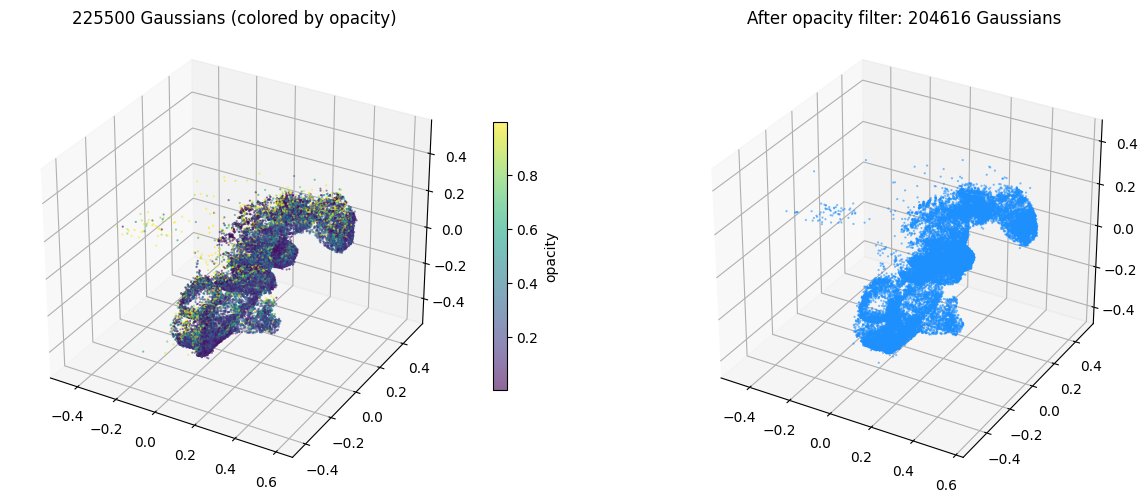

In [8]:
# --- Visualize: Gaussian cloud ---
import matplotlib
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

fig = plt.figure(figsize=(14, 5))

# Left: all Gaussians colored by opacity
ax1 = fig.add_subplot(121, projection="3d")
pos = gauss.positions.detach().cpu().numpy()
opa = gauss.opacity.detach().cpu().numpy()
rng = np.random.default_rng(SEED)
sub_idx = rng.choice(len(pos), size=min(30000, len(pos)), replace=False)
sc = ax1.scatter(pos[sub_idx, 0], pos[sub_idx, 1], pos[sub_idx, 2],
                 c=opa[sub_idx], s=0.3, cmap="viridis", alpha=0.6)
ax1.set_box_aspect(extent)
ax1.set_title(f"{len(gauss)} Gaussians (colored by opacity)")
plt.colorbar(sc, ax=ax1, shrink=0.6, label="opacity")

# Right: after opacity filter
ax2 = fig.add_subplot(122, projection="3d")
pos_f = gauss_f.positions.detach().cpu().numpy()
sub2 = rng.choice(len(pos_f), size=min(30000, len(pos_f)), replace=False)
ax2.scatter(pos_f[sub2, 0], pos_f[sub2, 1], pos_f[sub2, 2], s=0.3, c="dodgerblue", alpha=0.6)
ax2.set_box_aspect(extent)
ax2.set_title(f"After opacity filter: {len(gauss_f)} Gaussians")

plt.tight_layout()
plt.savefig(RUN_DIR / "01_gaussians.png", dpi=120, bbox_inches="tight")
plt.show()

## 7. Cameras / Rays + Visualize

[11:28:22] Loaded 64 REAL cameras from /notebooks/dataset/3DGS/3DGS/scan105_proper/scan105/cameras.json
  cam   0  img_name=0000.png              center=[ 0.796  0.083 -2.102]  cos(principal_ray, ->scene_center)=+0.997  OK
  cam   1  img_name=0008.png              center=[ 1.583 -0.229 -1.676]  cos(principal_ray, ->scene_center)=+1.000  OK
  cam   2  img_name=0016.png              center=[ 1.878 -0.467 -1.273]  cos(principal_ray, ->scene_center)=+0.999  OK
  cam   3  img_name=0024.png              center=[ 1.898  0.399 -1.296]  cos(principal_ray, ->scene_center)=+0.999  OK
  cam   4  img_name=0032.png              center=[ 1.956  0.695 -1.034]  cos(principal_ray, ->scene_center)=+0.997  OK
  cam   5  img_name=0040.png              center=[ 2.182 -0.517 -0.111]  cos(principal_ray, ->scene_center)=+0.993  OK
  cam   6  img_name=0048.png              center=[ 0.809  1.655 -1.157]  cos(principal_ray, ->scene_center)=+0.990  OK
  cam   7  img_name=0056.png              center=[ 2.836  0.522

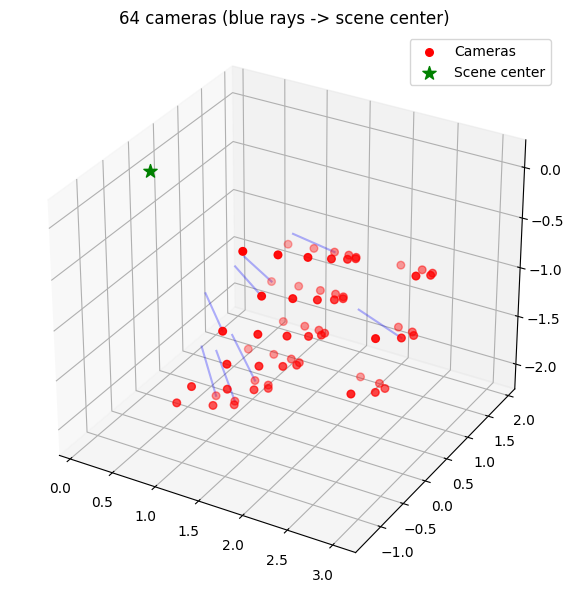

In [9]:
sc = CFG["synthetic_fallback"]

if cameras_json is not None:
    cams = camera.load_official_3dgs_cameras(cameras_json)
    log(f"Loaded {len(cams)} REAL cameras from {cameras_json}")
    USING_SYNTHETIC_CAMERAS = False
    CAMERA_SOURCE = "official_3dgs_cameras_json"
else:
    center = ((np.array(bounds_min) + np.array(bounds_max)) / 2).tolist()
    radius = 3.0 * float(np.max(np.array(bounds_max) - np.array(bounds_min)))
    cams = camera.synthetic_camera_ring(n_views=sc["n_synthetic_views"], radius=radius,
                                         H=sc["image_h"], W=sc["image_w"], focal=sc["focal"], center=center)
    USING_SYNTHETIC_CAMERAS = True
    CAMERA_SOURCE = "synthetic"

if not USING_SYNTHETIC_CAMERAS:
    scene_center = (np.array(bounds_min) + np.array(bounds_max)) / 2
    frac_ok = camera.sanity_check_cameras(cams, scene_center, verbose=True)
    assert frac_ok > 0.8, f"Only {frac_ok*100:.1f}% cameras OK — check R/T convention. STOPPING."

# --- Visualize: camera positions ---
fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(111, projection="3d")
cam_centers = np.array([c.center for c in cams])
ax.scatter(cam_centers[:, 0], cam_centers[:, 1], cam_centers[:, 2], c="red", s=30, label="Cameras")
scene_mid = (np.array(bounds_min) + np.array(bounds_max)) / 2
ax.scatter(*scene_mid, c="green", s=100, marker="*", label="Scene center")
# Draw a few principal rays
for i in range(0, len(cams), max(1, len(cams) // 8)):
    c = cams[i]
    direction = scene_mid - c.center
    direction = direction / np.linalg.norm(direction) * 0.5
    ax.plot([c.center[0], c.center[0] + direction[0]],
            [c.center[1], c.center[1] + direction[1]],
            [c.center[2], c.center[2] + direction[2]], "b-", alpha=0.3)
ax.set_box_aspect(extent)
ax.set_title(f"{len(cams)} cameras (blue rays -> scene center)")
ax.legend()
plt.tight_layout()
plt.savefig(RUN_DIR / "02_cameras.png", dpi=120, bbox_inches="tight")
plt.show()

## 8. Surface Sample Extraction (Transmittance-Crossing, Eq 3.2/3.3)

Paper core contribution #1. Cached to disk; skipped on re-run.

In [10]:
if FORCE_STAGE["surface_samples"]:
    with torch.no_grad():
        for name in ("positions", "opacity", "scales", "rotations", "colors"):
            getattr(gauss_f, name).copy_(getattr(gauss_pretrained_state, name).to(DEVICE))
    log("[RESET] Gaussians restored to pretrained baseline for surface extraction.")

surface_loaded = False
if SURFACE_CHECKPOINT.exists() and not FORCE_STAGE["surface_samples"]:
    payload = _torch_load(SURFACE_CHECKPOINT)
    if payload.get("run_hash") == RUN_HASH and payload.get("schema") == PIPELINE_SCHEMA:
        surface_points = payload["surface_points"].cpu()
        surface_normals = payload["surface_normals"].cpu()
        surface_loaded = True
        log(f"[LOAD] surface samples: {len(surface_points)} points")

if not surface_loaded:
    log(f"[RUN] surface extraction: stride={SURFACE_STRIDE}")
    all_pts, all_nrm = [], []
    for i, cam in enumerate(cams):
        origins, dirs, _ = cam.rays(DEVICE, stride=SURFACE_STRIDE)
        n_rays = origins.shape[0]
        log(f"  camera {i+1}/{len(cams)}: {n_rays} rays")
        for start in range(0, n_rays, SURFACE_RAY_BATCH_SIZE):
            end = min(start + SURFACE_RAY_BATCH_SIZE, n_rays)
            with torch.no_grad():
                pts, nrm, valid = transmittance.transmittance_crossing_points(
                    gauss_f, origins[start:end], dirs[start:end],
                    cull_sigma=CFG["transmittance"]["cull_sigma"],
                    max_candidates=CFG["transmittance"]["max_candidates_per_ray"])
            if len(pts):
                all_pts.append(pts.cpu())
                all_nrm.append(nrm.cpu())
            del pts, nrm, valid; gc.collect()
        del origins, dirs
        if torch.cuda.is_available(): torch.cuda.empty_cache()
        gc.collect()
    assert all_pts, "No surface samples recovered."
    surface_points = torch.cat(all_pts, dim=0)
    surface_normals = torch.cat(all_nrm, dim=0)
    _atomic_torch_save({"schema": PIPELINE_SCHEMA, "run_hash": RUN_HASH,
        "surface_points": surface_points, "surface_normals": surface_normals}, SURFACE_CHECKPOINT)
    log(f"[SAVE] surface samples: {len(surface_points)} points")

from src.utils import check_tensor
check_tensor("surface_points", surface_points)
check_tensor("surface_normals", surface_normals)
log(f"Surface samples ready: {len(surface_points)}")

[11:28:22] [RESET] Gaussians restored to pretrained baseline for surface extraction.
[11:28:22] [RUN] surface extraction: stride=16
[11:28:22]   camera 1/64: 7154 rays


/notebooks/Generated/SDF-GS-Refine-implementation/src/gaussian.py:181: UserWarning: Deterministic behavior was enabled with either `torch.use_deterministic_algorithms(True)` or `at::Context::setDeterministicAlgorithms(true)`, but this operation is not deterministic because it uses CuBLAS and you have CUDA >= 10.2. To enable deterministic behavior in this case, you must set an environment variable before running your PyTorch application: CUBLAS_WORKSPACE_CONFIG=:4096:8 or CUBLAS_WORKSPACE_CONFIG=:16:8. For more information, go to https://docs.nvidia.com/cuda/cublas/index.html#cublasApi_reproducibility (Triggered internally at ../aten/src/ATen/Context.cpp:156.)
  Sigma = R @ S2 @ R.transpose(1, 2)                        # (N,3,3)
/usr/local/lib/python3.11/dist-packages/torch/functional.py:385: UserWarning: Deterministic behavior was enabled with either `torch.use_deterministic_algorithms(True)` or `at::Context::setDeterministicAlgorithms(true)`, but this operation is not deterministic be

[11:28:29]   camera 2/64: 7154 rays
[11:28:35]   camera 3/64: 7154 rays
[11:28:42]   camera 4/64: 7154 rays
[11:28:49]   camera 5/64: 7154 rays
[11:28:55]   camera 6/64: 7154 rays
[11:29:02]   camera 7/64: 7154 rays
[11:29:08]   camera 8/64: 7154 rays
[11:29:15]   camera 9/64: 7154 rays
[11:29:21]   camera 10/64: 7154 rays
[11:29:28]   camera 11/64: 7154 rays
[11:29:35]   camera 12/64: 7154 rays
[11:29:41]   camera 13/64: 7154 rays
[11:29:47]   camera 14/64: 7154 rays
[11:29:54]   camera 15/64: 7154 rays
[11:30:00]   camera 16/64: 7154 rays
[11:30:06]   camera 17/64: 7154 rays
[11:30:13]   camera 18/64: 7154 rays
[11:30:20]   camera 19/64: 7154 rays
[11:30:26]   camera 20/64: 7154 rays
[11:30:33]   camera 21/64: 7154 rays
[11:30:39]   camera 22/64: 7154 rays
[11:30:45]   camera 23/64: 7154 rays
[11:30:52]   camera 24/64: 7154 rays
[11:30:59]   camera 25/64: 7154 rays
[11:31:05]   camera 26/64: 7154 rays
[11:31:12]   camera 27/64: 7154 rays
[11:31:18]   camera 28/64: 7154 rays
[11:31:25

[11:35:38] Surface points in cam 0: 165260/176575 (93.6%)


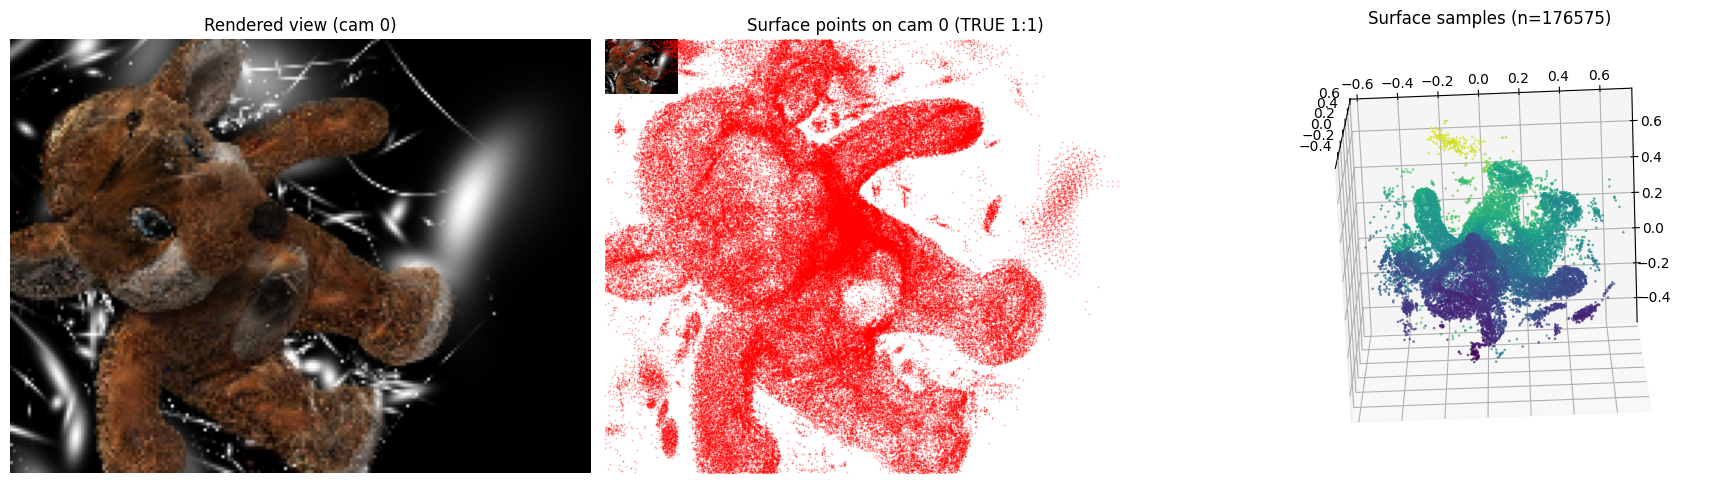

In [11]:
# --- Visualize: surface samples ---
DIAG_CAM_IDX = 0
diag_cam = cams[DIAG_CAM_IDX]
tc = CFG["transmittance"]

# Render view from cam 0
o_diag, d_diag, (ys_diag, xs_diag) = diag_cam.rays(DEVICE, stride=EVAL_RENDER_STRIDE)
chunks = []
for start in range(0, len(o_diag), EVAL_RENDER_BATCH_SIZE):
    end = min(start + EVAL_RENDER_BATCH_SIZE, len(o_diag))
    with torch.no_grad():
        rgb = losses.render_rays(gauss_f, o_diag[start:end], d_diag[start:end],
                                tc["cull_sigma"], tc["max_candidates_per_ray"])
    chunks.append(rgb.cpu())
    del rgb
if torch.cuda.is_available(): torch.cuda.empty_cache()
img_flat = torch.cat(chunks, dim=0).numpy()
uy, ux = np.unique(ys_diag), np.unique(xs_diag)
img_pred = img_flat.reshape(len(uy), len(ux), 3)

# Project surface points into cam 0 (TRUE 1:1)
X = surface_points.numpy()
Xc = (diag_cam.R @ X.T).T + diag_cam.t
in_front = Xc[:, 2] > 1e-6
Xc = Xc[in_front]
uvw = (diag_cam.K @ Xc.T).T
u_px = uvw[:, 0] / uvw[:, 2]
v_px = uvw[:, 1] / uvw[:, 2]
in_frame = (u_px >= 0) & (u_px < diag_cam.W) & (v_px >= 0) & (v_px < diag_cam.H)
u_px, v_px = u_px[in_frame], v_px[in_frame]
log(f"Surface points in cam {DIAG_CAM_IDX}: {len(u_px)}/{len(X)} ({100*len(u_px)/len(X):.1f}%)")

# Matched viewpoint for 3D scatter
scene_center = (np.array(bounds_min) + np.array(bounds_max)) / 2.0
view_dir = diag_cam.center - scene_center
r_xy = np.hypot(view_dir[0], view_dir[1])
diag_elev = float(np.degrees(np.arctan2(view_dir[2], r_xy)))
diag_azim = float(np.degrees(np.arctan2(view_dir[1], view_dir[0])))

fig = plt.figure(figsize=(18, 5))

ax1 = fig.add_subplot(131)
ax1.imshow(np.clip(img_pred, 0, 1))
ax1.set_title(f"Rendered view (cam {DIAG_CAM_IDX})")
ax1.axis("off")

ax2 = fig.add_subplot(132)
ax2.imshow(np.clip(img_pred, 0, 1))
ax2.scatter(u_px, v_px, s=1.5, c="red", alpha=0.35, linewidths=0)
ax2.set_xlim(0, diag_cam.W); ax2.set_ylim(diag_cam.H, 0)
ax2.set_title(f"Surface points on cam {DIAG_CAM_IDX} (TRUE 1:1)")
ax2.axis("off")

ax3 = fig.add_subplot(133, projection="3d")
sub = X[np.random.default_rng(SEED).choice(len(X), size=min(20000, len(X)), replace=False)]
ax3.scatter(sub[:, 0], sub[:, 1], sub[:, 2], s=0.8, c=sub[:, 2], cmap="viridis", alpha=0.6)
ax3.set_box_aspect(np.ptp(X, axis=0))
ax3.view_init(elev=diag_elev, azim=diag_azim)
ax3.set_title(f"Surface samples (n={len(X)})")

plt.tight_layout()
plt.savefig(RUN_DIR / "03_surface_samples.png", dpi=120, bbox_inches="tight")
plt.show()

## 9. SDF Network (Geometric Init, Gropp et al. 2020)

In [12]:
sdf_cfg = CFG["sdf_network"]
sdf_net = sdf.SDFNetwork(
    d_in=3, d_hidden=sdf_cfg["d_hidden"], n_layers=sdf_cfg["n_layers"],
    radius_init=sdf_cfg["radius_init"], beta=sdf_cfg["softplus_beta"]).to(DEVICE)
n_params = sum(p.numel() for p in sdf_net.parameters())
sdf_initial_state = {k: v.detach().cpu().clone() for k, v in sdf_net.state_dict().items()}
log(f"SDF MLP: {sdf_cfg['n_layers']}x{sdf_cfg['d_hidden']}, {n_params} parameters")

with torch.no_grad():
    f0, g0 = sdf_net.gradient(surface_points[:64].to(DEVICE))
log(f"Pre-refinement mean|f|={f0.abs().mean().item():.4f}, mean|grad|={g0.norm(dim=-1).mean().item():.4f}")

[11:35:40] SDF MLP: 8x256, 461825 parameters
[11:35:40] Pre-refinement mean|f|=0.3690, mean|grad|=1.0242


/usr/local/lib/python3.11/dist-packages/torch/nn/modules/linear.py:114: UserWarning: Deterministic behavior was enabled with either `torch.use_deterministic_algorithms(True)` or `at::Context::setDeterministicAlgorithms(true)`, but this operation is not deterministic because it uses CuBLAS and you have CUDA >= 10.2. To enable deterministic behavior in this case, you must set an environment variable before running your PyTorch application: CUBLAS_WORKSPACE_CONFIG=:4096:8 or CUBLAS_WORKSPACE_CONFIG=:16:8. For more information, go to https://docs.nvidia.com/cuda/cublas/index.html#cublasApi_reproducibility (Triggered internally at ../aten/src/ATen/Context.cpp:156.)
  return F.linear(input, self.weight, self.bias)
/usr/local/lib/python3.11/dist-packages/torch/autograd/__init__.py:394: UserWarning: Deterministic behavior was enabled with either `torch.use_deterministic_algorithms(True)` or `at::Context::setDeterministicAlgorithms(true)`, but this operation is not deterministic because it uses

## 10. Joint Refinement — Training (Paper Core Contribution #2)

L_total = L_photo + lambda_e * L_eikonal + lambda_n * L_normal

**Key fix:** Samples from cached 176K surface points (not recompute-per-iter).
Mesh snapshots every 1000 iters to visualize SDF convergence.

In [13]:
# --- Frozen photometric target ---
images_dir = camera.discover_images_dir(search_root_3dgs) if not USING_SYNTHETIC_CAMERAS else None
USING_SYNTHETIC_PHOTOMETRIC_TARGET = images_dir is None or CAMERA_SOURCE == "synthetic"

gauss_initial_state = gauss_pretrained_state.clone_detached()

if USING_SYNTHETIC_PHOTOMETRIC_TARGET:
    gauss_frozen_target = losses.build_frozen_photometric_target(gauss_initial_state.clone_detached())
    log("Photometric target = frozen pretrained render (perturbed 2% to avoid zero-gradient).")
    _diff = (gauss_frozen_target.positions - gauss_pretrained_state.positions).abs().mean().item()
    assert _diff > 0, "Frozen target still identical to pretrained — fix losses.py."
    log(f"  target vs pretrained pos diff = {_diff:.6f} (must be > 0)")
else:
    real_targets = {}
    for ci, cam in enumerate(cams):
        try:
            image = camera.load_image_for_camera(cam, images_dir, resize_to_camera=True)
            real_targets[ci] = torch.tensor(image, device=DEVICE)
        except FileNotFoundError:
            pass
    log(f"Loaded {len(real_targets)}/{len(cams)} real observed images.")

[11:35:40] Photometric target = frozen pretrained render (perturbed 2% to avoid zero-gradient).
[11:35:40]   target vs pretrained pos diff = 0.003641 (must be > 0)


In [14]:
import importlib
importlib.reload(mesh_mod)

rc = CFG["joint_refinement"]
N_ITERS = int(rc["n_iterations_smoke_test"])
BATCH = int(rc["batch_size_rays_smoke_test"])

# LR warm-up: 5x peak for first 15% of iters, then decay to normal
SDF_LR_WARMUP_FRAC = 0.15
SDF_LR_WARMUP_PEAK = 5.0

def _sdf_lr_multiplier(it, n_iters):
    warmup_iters = max(1, int(SDF_LR_WARMUP_FRAC * n_iters))
    if it < warmup_iters:
        return SDF_LR_WARMUP_PEAK - (SDF_LR_WARMUP_PEAK - 1.0) * (it / warmup_iters)
    return 1.0

params_gauss = [gauss_f.positions, gauss_f.opacity, gauss_f.scales, gauss_f.rotations, gauss_f.colors]
for p in params_gauss:
    p.requires_grad_(True)
opt_gauss = torch.optim.Adam(params_gauss, lr=rc["lr_gaussian"])
opt_sdf = torch.optim.Adam(sdf_net.parameters(), lr=rc["lr_sdf"])
loss_history = []
start_iteration = 0

def _copy_gaussian_state(state):
    with torch.no_grad():
        for name in ("positions", "opacity", "scales", "rotations", "colors"):
            t = getattr(gauss_f, name)
            s = state[name].to(device=t.device, dtype=t.dtype)
            t.copy_(s)

def _gaussian_state_cpu():
    return {n: getattr(gauss_f, n).detach().cpu().clone()
            for n in ("positions", "opacity", "scales", "rotations", "colors")}

def _save_training(next_it, completed=False):
    _atomic_torch_save({
        "schema": PIPELINE_SCHEMA, "run_hash": RUN_HASH,
        "next_iteration": int(next_it), "completed": bool(completed),
        "n_iterations": N_ITERS,
        "gaussian_state": _gaussian_state_cpu(),
        "sdf_state": {k: v.detach().cpu() for k, v in sdf_net.state_dict().items()},
        "opt_gauss_state": opt_gauss.state_dict(),
        "opt_sdf_state": opt_sdf.state_dict(),
        "loss_history": loss_history, "rng_state": _rng_state(),
    }, TRAIN_CHECKPOINT)

# --- Load or reset training state ---
if FORCE_STAGE["training"]:
    set_seed(SEED)
    _copy_gaussian_state({n: getattr(gauss_initial_state, n).detach().cpu()
                          for n in ("positions", "opacity", "scales", "rotations", "colors")})
    sdf_net.load_state_dict(sdf_initial_state)
    log("[RESET] Training from scratch.")

if TRAIN_CHECKPOINT.exists() and not FORCE_STAGE["training"]:
    ckpt = _torch_load(TRAIN_CHECKPOINT)
    compatible = (ckpt.get("schema") == PIPELINE_SCHEMA and ckpt.get("run_hash") == RUN_HASH
                  and ckpt.get("n_iterations") == N_ITERS)
    if compatible:
        _copy_gaussian_state(ckpt["gaussian_state"])
        sdf_net.load_state_dict(ckpt["sdf_state"])
        opt_gauss.load_state_dict(ckpt["opt_gauss_state"])
        opt_sdf.load_state_dict(ckpt["opt_sdf_state"])
        loss_history = ckpt.get("loss_history", [])
        start_iteration = int(ckpt.get("next_iteration", 0))
        _restore_rng_state(ckpt["rng_state"])
        label = "complete" if start_iteration >= N_ITERS else f"resume from {start_iteration}"
        log(f"[LOAD] checkpoint: {label}")

print(f"Training: iter {start_iteration}..{N_ITERS-1}, batch={BATCH}, "
      f"warmup={SDF_LR_WARMUP_PEAK}x for {int(SDF_LR_WARMUP_FRAC*100)}% iters")

[11:35:40] [RESET] Training from scratch.
Training: iter 0..9999, batch=1024, warmup=5.0x for 15% iters


In [15]:
# --- Training loop (FIXED: samples from cached surface points) ---
snapshot_meshes = {}  # iter_num -> (verts, faces) for convergence visualization

# Precompute a bounded ray batch per camera ONCE (photometric auxiliary term).
# Only used when REAL observed images are available for the photometric loss.
# When the photometric target is synthetic (no real images), this is skipped
# entirely because the frozen synthetic render carries almost no signal.
_pix_stride = max(1, int(np.sqrt(1_500_000.0 / max(BATCH, 1))))  # cap ~1.5M candidate rays
_cam_rays = {}
for _ci, _cam in enumerate(cams):
    _o, _d, (_ys, _xs) = _cam.rays(DEVICE, stride=_pix_stride)
    _cam_rays[_ci] = (_o, _d, np.asarray(_ys), np.asarray(_xs))

if start_iteration < N_ITERS:
    for it in range(start_iteration, N_ITERS):
        # LR warm-up
        current_sdf_lr = rc["lr_sdf"] * _sdf_lr_multiplier(it, N_ITERS)
        for g in opt_sdf.param_groups:
            g["lr"] = current_sdf_lr

        # ============================================================
        # Core fix: sample from cached surface points (not recomputing
        # transmittance-crossing each iteration). This supervises BATCH
        # points per step (vs ~25-59 from the old ray-recompute loop),
        # covering ALL cameras uniformly -> enough density to carve
        # ears / arms / legs instead of collapsing to a smooth shell.
        # ============================================================
        idx = torch.randperm(len(surface_points))[:BATCH]
        surf_pts = surface_points[idx].to(DEVICE)
        surf_nrm = surface_normals[idx].to(DEVICE)

        # Photometric term: ONLY when real observed images exist.
        # If the target is synthetic (frozen snapshot) we omit it - it adds
        # noise and huge GPU cost for ~zero positional signal.
        l_photo = None
        cam_idx = it % len(cams)
        if USING_SYNTHETIC_PHOTOMETRIC_TARGET:
            pass  # drop photometric entirely in synthetic-target mode
        else:
            _o, _d, _ys, _xs = _cam_rays[cam_idx]
            _perm = torch.randperm(_o.shape[0], device=DEVICE)[:BATCH]
            origins, dirs = _o[_perm], _d[_perm]
            ys, xs = _ys[_perm.cpu()], _xs[_perm.cpu()]
            if real_targets.get(cam_idx) is not None:
                target_image = real_targets[cam_idx]
                target_y = torch.as_tensor(ys[:BATCH], device=DEVICE, dtype=torch.long)
                target_x = torch.as_tensor(xs[:BATCH], device=DEVICE, dtype=torch.long)
                target_rgb = target_image[target_y, target_x, :]
                l_photo, rendered = losses.photometric_loss(
                    gauss_f, origins, dirs, target_rgb,
                    tc["cull_sigma"], tc["max_candidates_per_ray"])

        step_ran = len(surf_pts) > 0
        if step_ran:
            # SDF losses on cached surface points (primary supervision)
            f_s, grad_s = sdf_net.gradient(surf_pts)
            l_normal = losses.normal_and_boundary_loss(f_s, grad_s, surf_nrm)

            lo = torch.tensor(bounds_min, device=DEVICE)
            hi = torch.tensor(bounds_max, device=DEVICE)
            domain_pts = lo + torch.rand(256, 3, device=DEVICE) * (hi - lo)
            _, grad_d = sdf_net.gradient(domain_pts)
            l_eik = losses.eikonal_loss(grad_d)

            total_loss = rc["lambda_eikonal"] * l_eik + rc["lambda_normal"] * l_normal
            if l_photo is not None:
                total_loss = total_loss + l_photo

            opt_gauss.zero_grad()
            opt_sdf.zero_grad()
            total_loss.backward()
            opt_gauss.step()
            opt_sdf.step()

            loss_history.append({
                "it": it, "total": total_loss.item(),
                "photo": l_photo.item() if l_photo is not None else 0.0,
                "eikonal": l_eik.item(), "normal": l_normal.item(),
                "n_surf": int(len(surf_pts)), "sdf_lr": current_sdf_lr,
            })

            # Print progress every 500 iters
            if it % 500 == 0 or it == N_ITERS - 1:
                _ph = f"{l_photo.item():.5f}" if l_photo is not None else "  (off)"
                log(f"  iter {it:5d} total={total_loss.item():.5f} photo={_ph} "
                    f"eikonal={l_eik.item():.5f} normal={l_normal.item():.5f} "
                    f"n_surf={len(surf_pts)} sdf_lr={current_sdf_lr:.2e}")

            # --- Mesh snapshot every SNAPSHOT_EVERY iters ---
            if (it + 1) % SNAPSHOT_EVERY == 0:
                log(f"  [SNAPSHOT] extracting mesh at iter {it+1}...")
                snap_v, snap_f = mesh_mod.extract_mesh(
                    sdf_net, bounds_min, bounds_max,
                    CFG["mesh_extraction"]["grid_resolution_smoke_test"], DEVICE)
                if snap_v is not None:
                    snapshot_meshes[it + 1] = (snap_v, snap_f)
                    snap_path = SNAPSHOTS_DIR / f"mesh_iter_{it+1:05d}.npz"
                    np.savez_compressed(snap_path, verts=snap_v, faces=snap_f)
                    log(f"  [SNAPSHOT] saved: V={len(snap_v)}, F={len(snap_f)}")

        # Checkpoint
        next_iteration = it + 1
        if next_iteration % TRAIN_CHECKPOINT_EVERY == 0 or next_iteration == N_ITERS:
            _save_training(next_iteration, completed=next_iteration >= N_ITERS)

        del surf_pts, surf_nrm
        if l_photo is not None:
            del origins, dirs
        gc.collect()

    log("Training complete.")
else:
    log("[SKIP] Training already complete from checkpoint.")


[11:35:40]   iter     0 total=0.14572 photo=  (off) eikonal=0.04964 normal=0.71617 n_surf=1024 sdf_lr=2.50e-03


/usr/local/lib/python3.11/dist-packages/torch/nn/modules/linear.py:114: UserWarning: Deterministic behavior was enabled with either `torch.use_deterministic_algorithms(True)` or `at::Context::setDeterministicAlgorithms(true)`, but this operation is not deterministic because it uses CuBLAS and you have CUDA >= 10.2. To enable deterministic behavior in this case, you must set an environment variable before running your PyTorch application: CUBLAS_WORKSPACE_CONFIG=:4096:8 or CUBLAS_WORKSPACE_CONFIG=:16:8. For more information, go to https://docs.nvidia.com/cuda/cublas/index.html#cublasApi_reproducibility (Triggered internally at ../aten/src/ATen/Context.cpp:156.)
  return F.linear(input, self.weight, self.bias)
/usr/local/lib/python3.11/dist-packages/torch/autograd/__init__.py:394: UserWarning: Deterministic behavior was enabled with either `torch.use_deterministic_algorithms(True)` or `at::Context::setDeterministicAlgorithms(true)`, but this operation is not deterministic because it uses

[11:36:57]   iter   500 total=0.07154 photo=  (off) eikonal=0.03739 normal=0.34835 n_surf=1024 sdf_lr=1.83e-03
[11:38:13]   [SNAPSHOT] extracting mesh at iter 1000...
[11:38:14]   [SNAPSHOT] saved: V=56398, F=112245
[11:38:14]   iter  1000 total=0.06779 photo=  (off) eikonal=0.03472 normal=0.33024 n_surf=1024 sdf_lr=1.17e-03
[11:39:31]   iter  1500 total=0.06487 photo=  (off) eikonal=0.02623 normal=0.31778 n_surf=1024 sdf_lr=5.00e-04
[11:40:49]   [SNAPSHOT] extracting mesh at iter 2000...
[11:40:49]   [SNAPSHOT] saved: V=58388, F=116223
[11:40:49]   iter  2000 total=0.06465 photo=  (off) eikonal=0.02715 normal=0.31645 n_surf=1024 sdf_lr=5.00e-04
[11:42:08]   iter  2500 total=0.06719 photo=  (off) eikonal=0.02942 normal=0.32859 n_surf=1024 sdf_lr=5.00e-04
[11:43:26]   [SNAPSHOT] extracting mesh at iter 3000...
[11:43:27]   [SNAPSHOT] saved: V=64429, F=128213
[11:43:27]   iter  3000 total=0.06886 photo=  (off) eikonal=0.02166 normal=0.33886 n_surf=1024 sdf_lr=5.00e-04
[11:44:44]   iter  

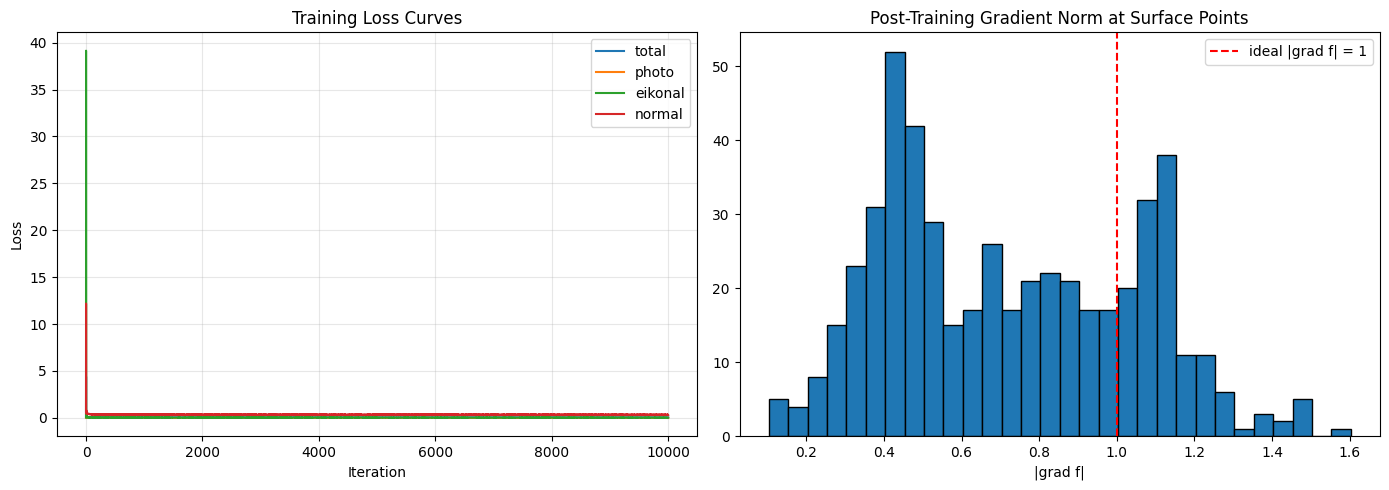

[12:01:45] Post-refinement mean|f|=0.0356, mean|grad|=0.7203


In [16]:
# --- Visualize: training convergence ---
if loss_history:
    its = [h["it"] for h in loss_history]
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    # Loss curves
    for key in ("total", "photo", "eikonal", "normal"):
        axes[0].plot(its, [h[key] for h in loss_history], label=key)
    axes[0].set_xlabel("Iteration")
    axes[0].set_ylabel("Loss")
    axes[0].set_title("Training Loss Curves")
    axes[0].legend()
    axes[0].grid(True, alpha=0.3)

    # Gradient norm histogram
    with torch.no_grad():
        f_final, grad_final = sdf_net.gradient(surface_points[:512].to(DEVICE))
    axes[1].hist(grad_final.norm(dim=-1).detach().cpu().numpy(), bins=30, edgecolor="black")
    axes[1].axvline(1.0, color="r", linestyle="--", label="ideal |grad f| = 1")
    axes[1].set_title("Post-Training Gradient Norm at Surface Points")
    axes[1].set_xlabel("|grad f|")
    axes[1].legend()

    plt.tight_layout()
    plt.savefig(RUN_DIR / "04_loss_and_gradient.png", dpi=120, bbox_inches="tight")
    plt.show()

    log(f"Post-refinement mean|f|={f_final.detach().abs().mean().item():.4f}, "
        f"mean|grad|={grad_final.norm(dim=-1).detach().mean().item():.4f}")

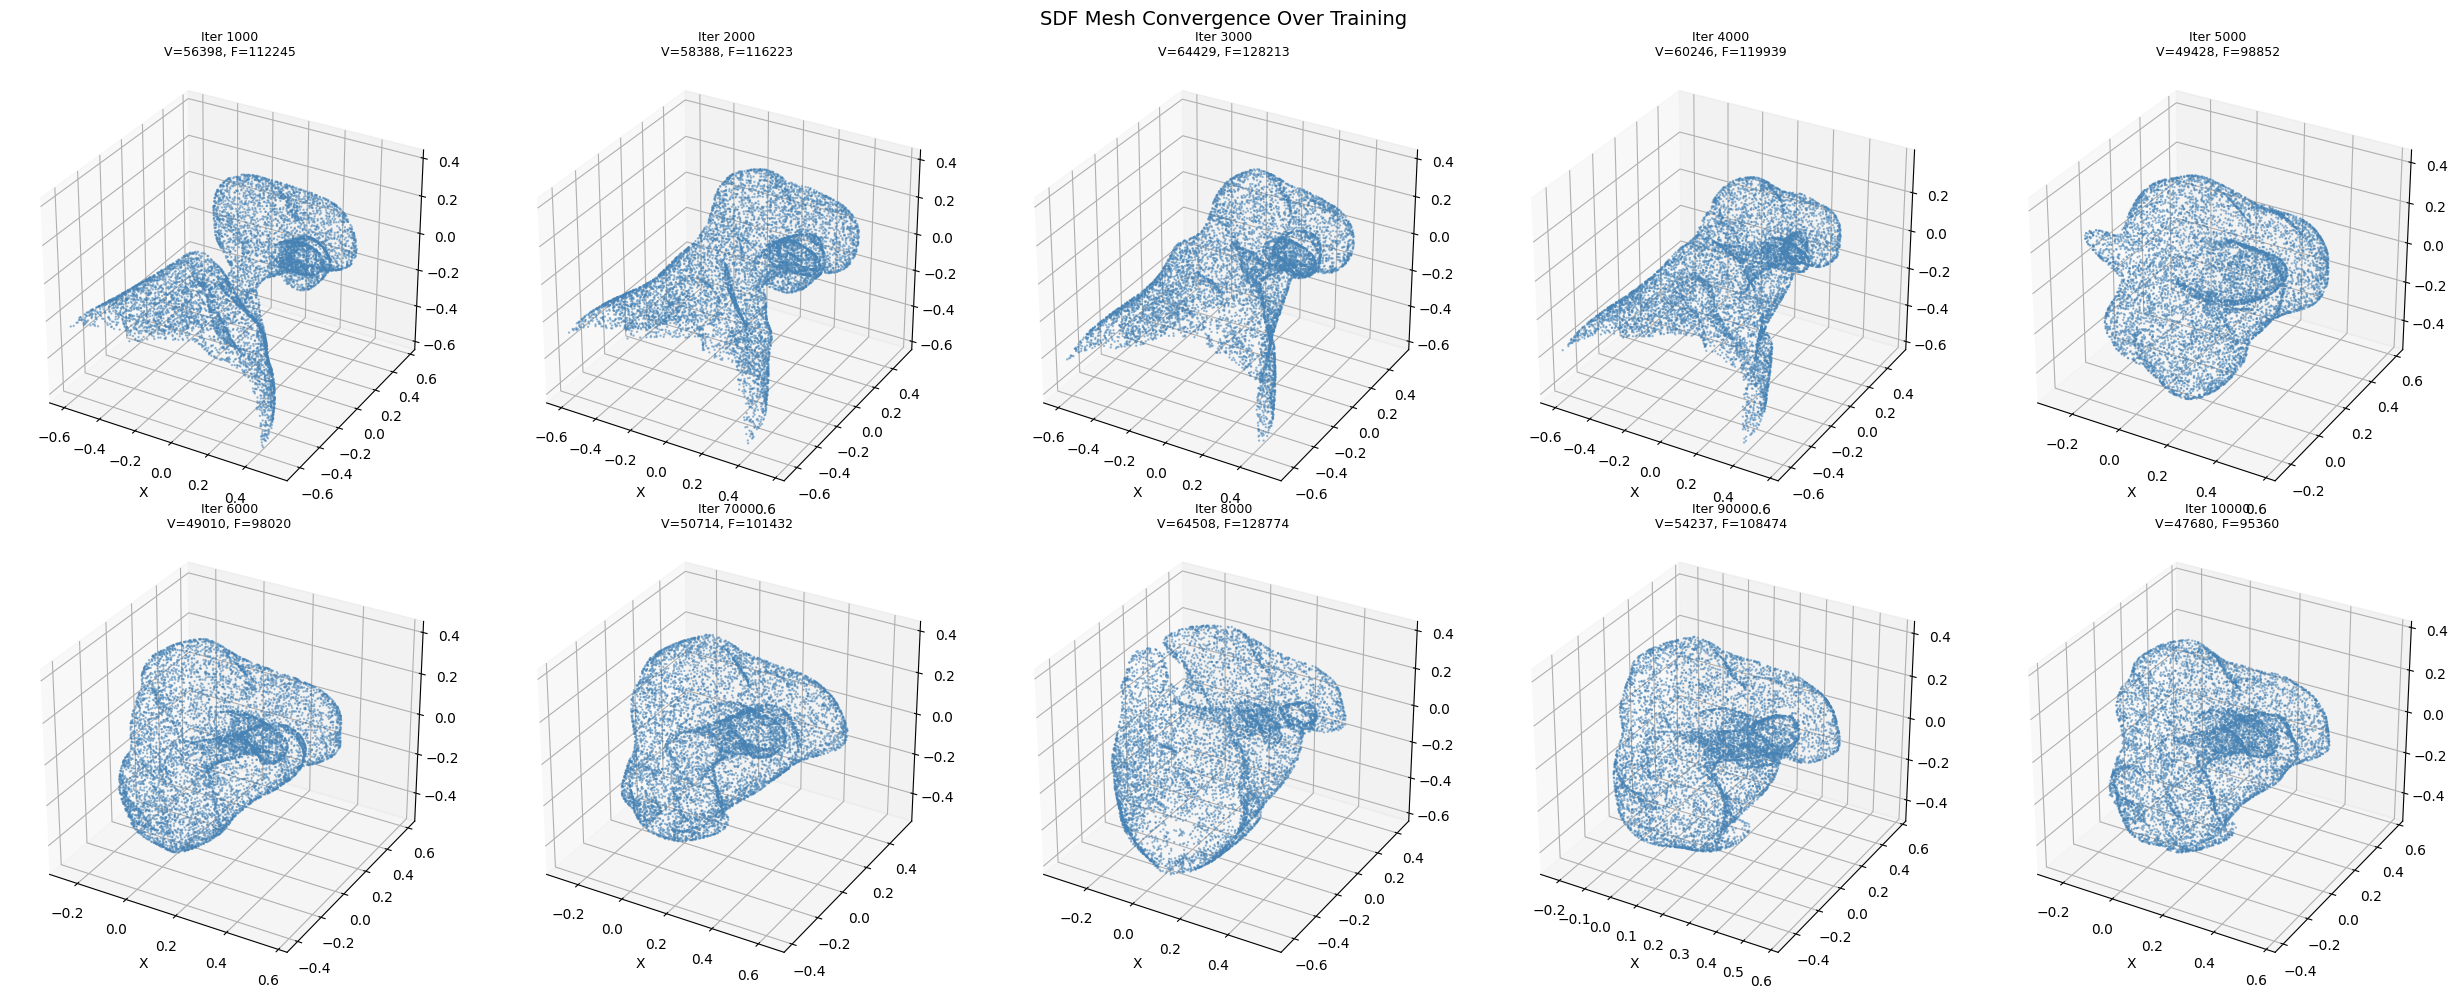

In [17]:
# --- Visualize: mesh convergence snapshots ---
if snapshot_meshes:
    n_snaps = len(snapshot_meshes)
    cols = min(n_snaps, 5)
    rows = (n_snaps + cols - 1) // cols
    fig = plt.figure(figsize=(5 * cols, 5 * rows))
    scene_mid = np.array([(bmin[i] + bmax[i]) / 2 for i in range(3)])
    for idx, (it_num, (sv, sf)) in enumerate(sorted(snapshot_meshes.items())):
        ax = fig.add_subplot(rows, cols, idx + 1, projection="3d")
        mesh_snap = trimesh.Trimesh(vertices=sv, faces=sf)
        # Subsample vertices for plotting
        rng_snap = np.random.default_rng(42)
        vsub = sv[rng_snap.choice(len(sv), size=min(8000, len(sv)), replace=False)]
        ax.scatter(vsub[:, 0], vsub[:, 1], vsub[:, 2], s=0.5, c="steelblue", alpha=0.5)
        ax.set_box_aspect(extent)
        ax.set_title(f"Iter {it_num}\nV={len(sv)}, F={len(sf)}", fontsize=9)
        ax.set_xlabel("X")
    plt.suptitle("SDF Mesh Convergence Over Training", fontsize=14)
    plt.tight_layout()
    plt.savefig(RUN_DIR / "05_mesh_convergence.png", dpi=120, bbox_inches="tight")
    plt.show()
else:
    print("No mesh snapshots captured (SNAPSHOT_EVERY may not have been reached).")

## 11. Mesh Extraction (Marching Cubes, isovalue=0)

In [18]:
raw_mesh_loaded = False
if RAW_MESH_CHECKPOINT.exists() and not FORCE_STAGE["mesh"]:
    raw = np.load(RAW_MESH_CHECKPOINT)
    verts, faces = raw["verts"], raw["faces"]
    raw_mesh_loaded = True
    log(f"[LOAD] raw mesh: V={len(verts)}, F={len(faces)}")

if not raw_mesh_loaded:
    resolution = CFG["mesh_extraction"]["grid_resolution_smoke_test"]
    log(f"[RUN] Marching Cubes on {resolution}^3 grid")
    verts, faces = mesh_mod.extract_mesh(sdf_net, bounds_min, bounds_max, resolution, DEVICE)
    assert verts is not None, "Marching Cubes found no zero-crossing."
    np.savez_compressed(RAW_MESH_CHECKPOINT, verts=verts, faces=faces)
    log(f"[SAVE] raw mesh: V={len(verts)}, F={len(faces)}")
log(f"Raw mesh: {len(verts)} vertices, {len(faces)} faces")

[12:01:49] [RUN] Marching Cubes on 160^3 grid
[12:01:49] [SAVE] raw mesh: V=47680, F=95360
[12:01:49] Raw mesh: 47680 vertices, 95360 faces


## 12. Mesh Post-Processing (Subbab 3.7)

In [19]:
processed_loaded = False
if METRIC_MESH_PATH.exists() and VIZ_MESH_PATH.exists() and not FORCE_STAGE["mesh"]:
    mesh_for_metrics = trimesh.load(METRIC_MESH_PATH, process=False)
    mesh_for_viz = trimesh.load(VIZ_MESH_PATH, process=False)
    processed_loaded = True
    log("[LOAD] processed meshes")

if not processed_loaded:
    pp = CFG["mesh_postprocess"]
    mesh_for_metrics, mesh_for_viz = mesh_mod.postprocess(
        verts, faces,
        min_component_frac=pp["min_component_area_fraction"],
        max_hole_edges=pp["max_hole_boundary_edges"],
        keep_only_largest=True,
        laplacian_smooth=True,
        laplacian_iters=pp["laplacian_smoothing_iters"],
        laplacian_lambda=pp["laplacian_smoothing_lambda"])
    assert mesh_mod.validate_mesh(mesh_for_metrics, "mesh_for_metrics")
    mesh_mod.validate_mesh(mesh_for_viz, "mesh_for_visualization")
    mesh_mod.save_mesh(mesh_for_metrics, METRIC_MESH_PATH)
    mesh_mod.save_mesh(mesh_for_viz, VIZ_MESH_PATH)
    log("[SAVE] processed meshes")

== Mesh component diagnostic: 5 connected component(s) found ==
  component 0: area=2.115844  frac_of_largest=1.0000  V=47678  F=95356  centroid=[ 0.1579 -0.0066 -0.0016]
  component 1: area=0.000000  frac_of_largest=0.0000  V=2  F=1  centroid=[ 0.1401  0.4832 -0.3109]
  component 2: area=0.000000  frac_of_largest=0.0000  V=1  F=1  centroid=[ 0.1421  0.4862 -0.3109]
  component 3: area=0.000000  frac_of_largest=0.0000  V=2  F=1  centroid=[ 0.145   0.4862 -0.3092]
  component 4: area=0.000000  frac_of_largest=0.0000  V=2  F=1  centroid=[ 0.1421  0.4891 -0.3114]
== Mesh validation: mesh_for_metrics ==
  vertices=47678  faces=95356  NaN/Inf=False  VALID=True
== Mesh validation: mesh_for_visualization ==
  vertices=47678  faces=95356  NaN/Inf=False  VALID=True
[12:01:50] [SAVE] processed meshes


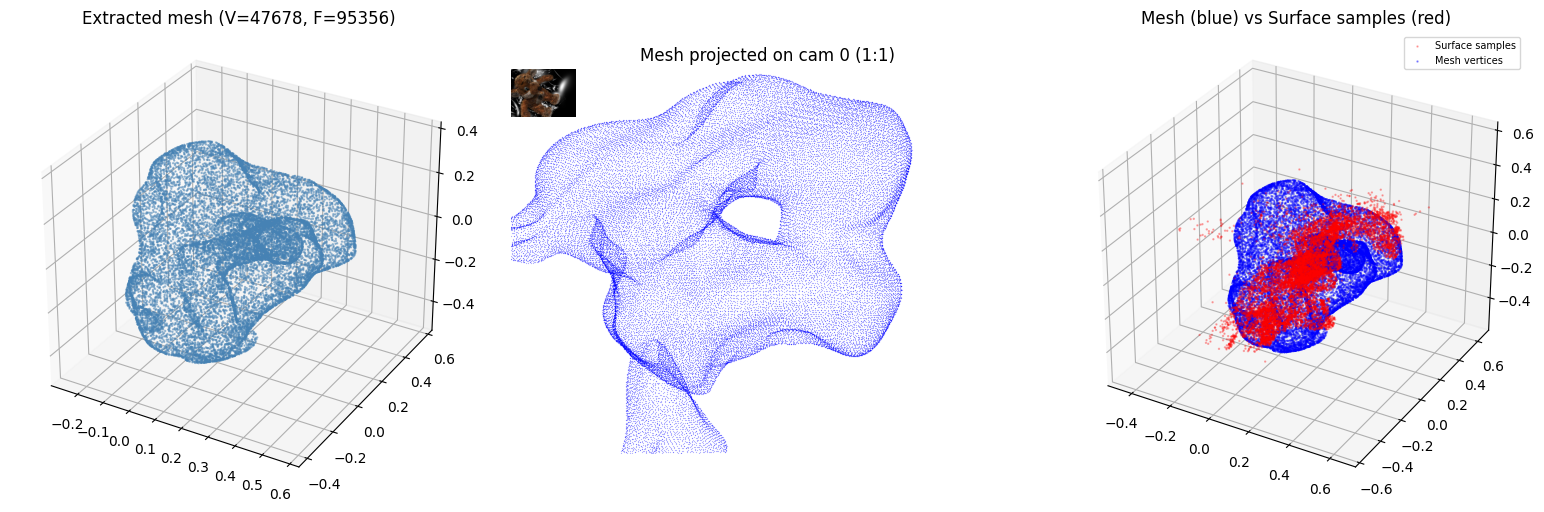

In [20]:
# --- Visualize: extracted mesh ---
fig = plt.figure(figsize=(16, 5))
mv = np.asarray(mesh_for_viz.vertices)
mf = np.asarray(mesh_for_viz.faces)
rng_m = np.random.default_rng(SEED)

# Panel 1: mesh from default view
ax1 = fig.add_subplot(131, projection="3d")
vsub = mv[rng_m.choice(len(mv), size=min(15000, len(mv)), replace=False)]
ax1.scatter(vsub[:, 0], vsub[:, 1], vsub[:, 2], s=0.5, c="steelblue", alpha=0.5)
ax1.set_box_aspect(extent)
ax1.set_title(f"Extracted mesh (V={len(mv)}, F={len(mf)})")

# Panel 2: mesh projected onto cam 0
ax2 = fig.add_subplot(132)
ax2.imshow(np.clip(img_pred, 0, 1))
Xm = mv
Xmc = (diag_cam.R @ Xm.T).T + diag_cam.t
front = Xmc[:, 2] > 1e-6
Xmc = Xmc[front]
uvwm = (diag_cam.K @ Xmc.T).T
um = uvwm[:, 0] / uvwm[:, 2]
vm = uvwm[:, 1] / uvwm[:, 2]
inf = (um >= 0) & (um < diag_cam.W) & (vm >= 0) & (vm < diag_cam.H)
ax2.scatter(um[inf], vm[inf], s=0.8, c="blue", alpha=0.3, linewidths=0)
ax2.set_xlim(0, diag_cam.W); ax2.set_ylim(diag_cam.H, 0)
ax2.set_title("Mesh projected on cam 0 (1:1)")
ax2.axis("off")

# Panel 3: mesh vs surface samples overlay
ax3 = fig.add_subplot(133, projection="3d")
ssub = X[rng_m.choice(len(X), size=min(10000, len(X)), replace=False)]
ax3.scatter(ssub[:, 0], ssub[:, 1], ssub[:, 2], s=0.5, c="red", alpha=0.3, label="Surface samples")
ax3.scatter(vsub[:, 0], vsub[:, 1], vsub[:, 2], s=0.5, c="blue", alpha=0.4, label="Mesh vertices")
ax3.set_box_aspect(extent)
ax3.set_title("Mesh (blue) vs Surface samples (red)")
ax3.legend(fontsize=7)

plt.tight_layout()
plt.savefig(RUN_DIR / "06_extracted_mesh.png", dpi=120, bbox_inches="tight")
plt.show()

## 13. Evaluation (Chamfer / F-score vs DTU Ground Truth)

In [21]:
import itertools, re
from scipy.spatial import cKDTree

def discover_exact_dtu_gt(root, scan):
    match = re.search(r"(\d+)$", str(scan))
    assert match, f"Cannot extract DTU id from {scan!r}"
    scan_id = int(match.group(1))
    wanted = [f"stl{scan_id:03d}_total.ply", f"stl{scan_id:03d}.ply",
              f"scan{scan_id}_total.ply", f"scan{scan_id}.ply"]
    by_name = {}
    for p in Path(root).rglob("*"):
        if p.is_file():
            by_name.setdefault(p.name.lower(), []).append(p)
    for name in wanted:
        hits = by_name.get(name.lower(), [])
        if hits:
            return hits[0]
    raise FileNotFoundError(f"No GT for {scan} under {root}. Expected: {wanted}")

def _mesh_points(mesh, count, seed):
    rng_state = np.random.get_state()
    np.random.seed(seed)
    try:
        if hasattr(mesh, "faces") and len(getattr(mesh, "faces", [])) > 0:
            pts, _ = trimesh.sample.sample_surface(mesh, count)
        else:
            verts = np.asarray(mesh.vertices)
            pts = verts[np.random.choice(len(verts), size=min(count, len(verts)), replace=False)]
    finally:
        np.random.set_state(rng_state)
    return np.asarray(pts, dtype=np.float64)

def _umeyama_similarity(source, target):
    sm, tm = source.mean(0), target.mean(0)
    x, y = source - sm, target - tm
    cov = (y.T @ x) / len(source)
    u, s, vt = np.linalg.svd(cov)
    corr = np.eye(3); corr[-1, -1] = np.sign(np.linalg.det(u @ vt))
    rot = u @ corr @ vt
    var = np.mean(np.sum(x * x, axis=1))
    scale = float(np.sum(s * np.diag(corr)) / max(var, 1e-12))
    trans = tm - scale * (rot @ sm)
    return scale, rot, trans

def _matrix_from_sim3(scale, rotation, translation):
    matrix = np.eye(4)
    matrix[:3, :3] = scale * rotation
    matrix[:3, 3] = translation
    return matrix

def robust_similarity_icp(source, target, iterations=20, trim_fraction=0.65):
    # Robust PCA + permutation-init similarity ICP (mirrors the reference notebook)
    source_center = np.median(source, axis=0)
    target_center = np.median(target, axis=0)
    src0, tgt0 = source - source_center, target - target_center
    src_scale = np.percentile(np.linalg.norm(src0, axis=1), 80)
    tgt_scale = np.percentile(np.linalg.norm(tgt0, axis=1), 80)
    initial_scale = float(tgt_scale / max(src_scale, 1e-12))
    _, src_axes = np.linalg.eigh(np.cov(src0.T))
    _, tgt_axes = np.linalg.eigh(np.cov(tgt0.T))
    src_axes, tgt_axes = src_axes[:, ::-1], tgt_axes[:, ::-1]
    tree = cKDTree(target)
    best = None
    probe = source[::max(1, len(source) // 3000)]
    for permutation in itertools.permutations(range(3)):
        permuted = src_axes[:, permutation]
        for signs in itertools.product((-1.0, 1.0), repeat=3):
            candidate_axes = permuted @ np.diag(signs)
            rotation = tgt_axes @ candidate_axes.T
            if np.linalg.det(rotation) < 0:
                continue
            translation = target_center - initial_scale * (rotation @ source_center)
            transformed = initial_scale * (probe @ rotation.T) + translation
            distances, _ = tree.query(transformed, k=1)
            score = float(np.median(distances))
            if best is None or score < best[0]:
                best = (score, initial_scale, rotation, translation)
    _, scale, rotation, translation = best
    for _ in range(iterations):
        transformed = scale * (source @ rotation.T) + translation
        distances, indices = tree.query(transformed, k=1)
        cutoff = np.quantile(distances, trim_fraction)
        keep = distances <= cutoff
        new_scale, new_rotation, new_translation = _umeyama_similarity(source[keep], target[indices[keep]])
        if not (0.2 * initial_scale <= new_scale <= 5.0 * initial_scale):
            break
        delta = abs(new_scale - scale) / max(scale, 1e-12) + np.linalg.norm(new_translation - translation) / max(tgt_scale, 1e-12)
        scale, rotation, translation = new_scale, new_rotation, new_translation
        if delta < 1e-7:
            break
    return _matrix_from_sim3(scale, rotation, translation)

if USING_SYNTHETIC:
    gt_path = None
    gt_mesh = synthetic.ground_truth_sphere_mesh(
        radius=CFG["synthetic_fallback"]["sphere_radius"], subdivisions=4)
    alignment_matrix = np.eye(4)  # synthetic scene is already in canonical frame
    scale_est = 1.0
    log("GT mesh: analytic synthetic sphere (identity alignment)")
    log(f"GT: {len(gt_mesh.vertices)} vertices, {len(getattr(gt_mesh, 'faces', []))} faces")
else:
    gt_path = discover_exact_dtu_gt(search_root_gt, scan_name)
    log(f"GT mesh: {gt_path}")
    gt_mesh = evaluation.load_gt_mesh(str(gt_path))
    log(f"GT: {len(gt_mesh.vertices)} vertices, {len(getattr(gt_mesh, 'faces', []))} faces")

n_eval = 50000

if USING_SYNTHETIC:
    # No registration needed for the canonical synthetic sphere.
    mesh_for_metrics.apply_transform(alignment_matrix)
    mesh_for_viz.apply_transform(alignment_matrix)
    mv_aligned = np.asarray(mesh_for_viz.vertices)
else:
    # Registration-assisted similarity-ICP diagnostic (mirrors reference notebook).
    source = _mesh_points(mesh_for_metrics, 12_000, SEED + 101)
    target = _mesh_points(gt_mesh, 20_000, SEED + 102)
    alignment_matrix = robust_similarity_icp(source, target)
    scale_est = float(np.linalg.norm(alignment_matrix[:3, :3], axis=0).mean())
    log(f"Alignment: mode=similarity_icp, scale={scale_est:.4f}")
    mesh_for_metrics.apply_transform(alignment_matrix)
    mesh_for_viz.apply_transform(alignment_matrix)
    mv_aligned = np.asarray(mesh_for_viz.vertices)

# Metrics in DTU mm units: thresholds are metres in config -> convert x1000
thresholds_mm = tuple(float(v) * EVAL_GT_UNITS_PER_METER for v in CFG["evaluation"]["f_score_thresholds_m"])
cd = evaluation.chamfer_distance(mesh_for_metrics, gt_mesh, n_points=n_eval, seed=SEED)
fs = evaluation.f_score(mesh_for_metrics, gt_mesh, thresholds=thresholds_mm,
                        n_points=n_eval, seed=SEED)

print("\n" + "="*50)
print("EVALUATION RESULTS (units: mm)")
print("="*50)
print(f"Chamfer distance:  {cd['chamfer_distance']:.2f} mm")
print(f"  pred->gt mean:   {cd['pred_to_gt_mean']:.2f} mm")
print(f"  gt->pred mean:   {cd['gt_to_pred_mean']:.2f} mm")
for th_mm in thresholds_mm:
    key = f"f_score@{th_mm}"
    r = fs[key]
    print(f"F-score@{th_mm:.0f}mm:  F1={r['f1']:.4f}  P={r['precision']:.4f}  R={r['recall']:.4f}")
print("="*50)

# Save results (strip _ internal keys for JSON serialization)
def _clean(d):
    return {k: (_clean(v) if isinstance(v, dict) else v)
            for k, v in d.items() if not (isinstance(k, str) and k.startswith("_"))}
results_clean = {"chamfer": _clean(cd), "f_scores": _clean(fs),
                 "alignment_scale": float(scale_est)}
with open(FINAL_RESULTS_PATH, "w") as fp:
    json.dump(results_clean, fp, indent=2)
log(f"Results saved to {FINAL_RESULTS_PATH}")

[12:01:52] GT mesh: /notebooks/dataset/DTU/dtu ground truth/Points/stl/stl105_total.ply
[12:01:52] GT: 4577222 vertices, 0 faces
[12:01:54] Alignment: mode=similarity_icp, scale=322.5037

EVALUATION RESULTS (units: mm)
Chamfer distance:  31.67 mm
  pred->gt mean:   19.61 mm
  gt->pred mean:   43.73 mm
F-score@1mm:  F1=0.0100  P=0.0101  R=0.0099
F-score@5mm:  F1=0.1248  P=0.1278  R=0.1220
[12:01:55] Results saved to /notebooks/Generated/SDF-GS-Refine-implementation/run_artifacts/scan105-498cee738663c8be/results.json


## 14. Final Pipeline Visualization

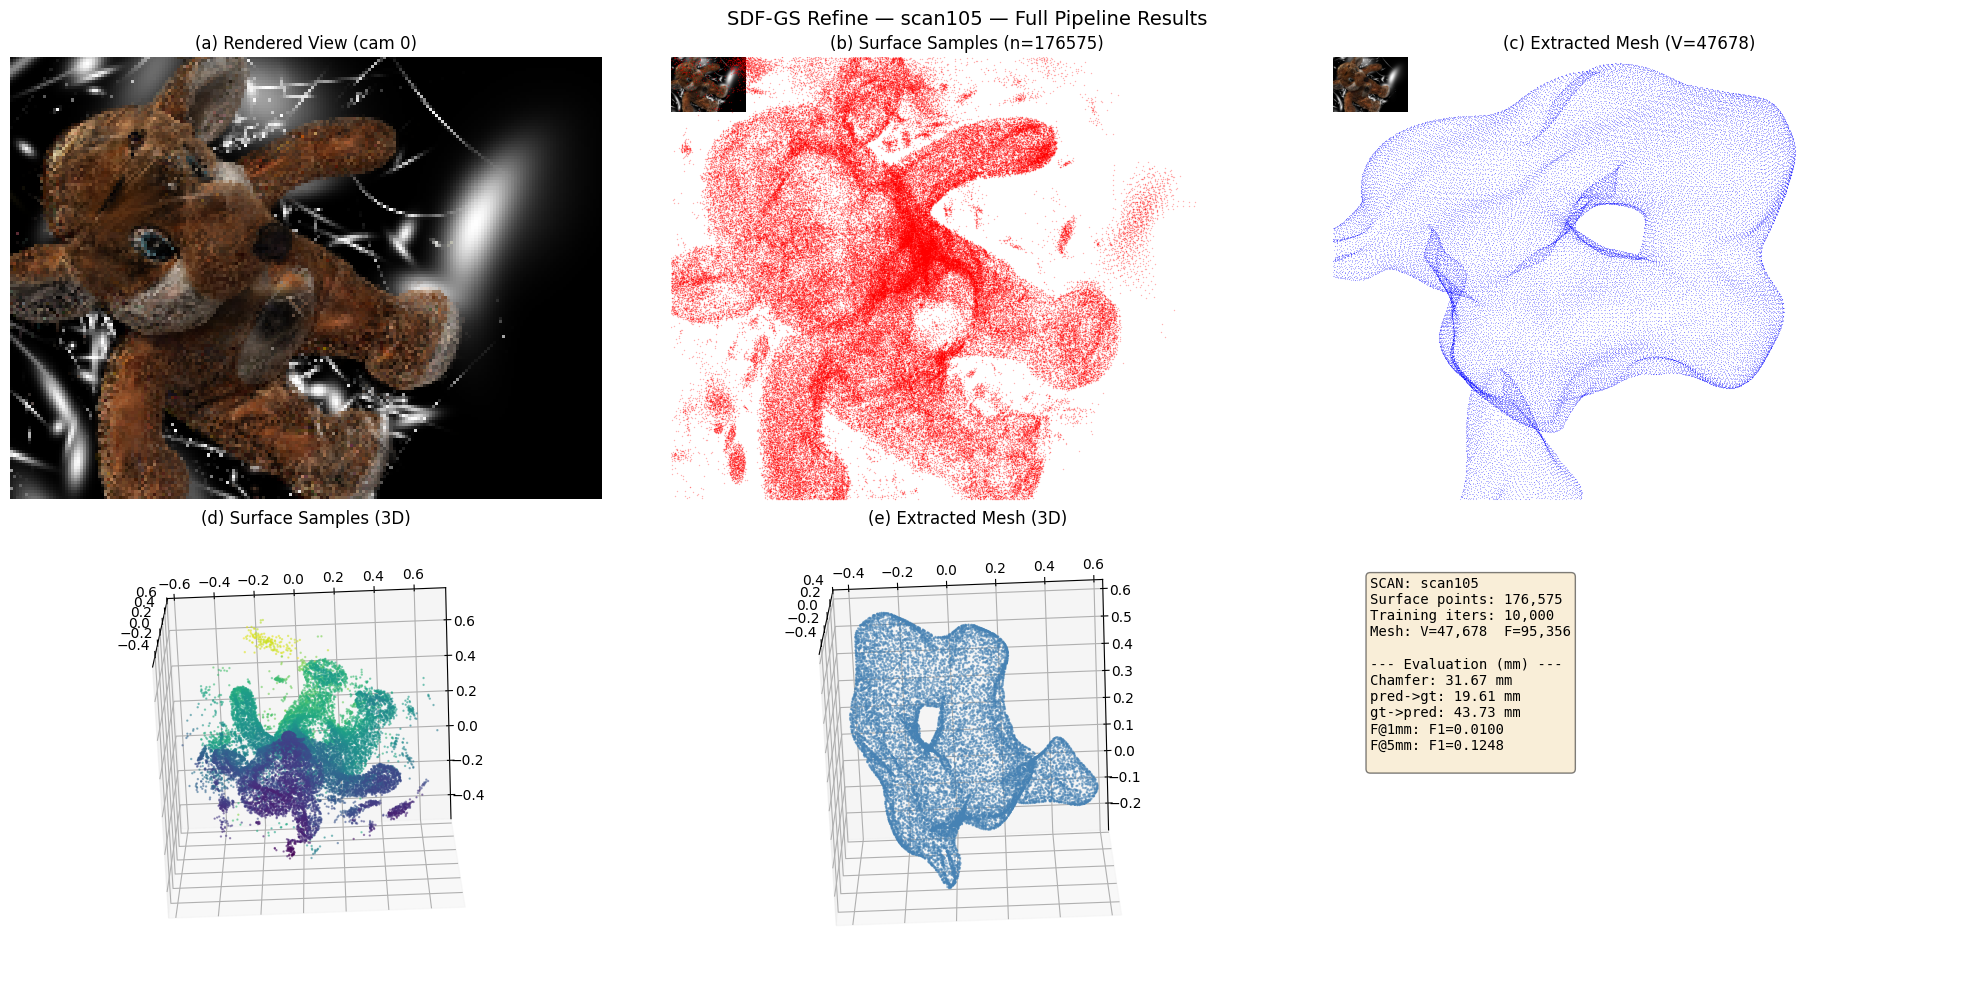

[12:01:57] Final visualization saved to /notebooks/Generated/SDF-GS-Refine-implementation/run_artifacts/scan105-498cee738663c8be/07_pipeline_visualization.png


In [22]:
fig = plt.figure(figsize=(20, 10))

# 1. Rendered view
ax1 = fig.add_subplot(231)
ax1.imshow(np.clip(img_pred, 0, 1))
ax1.set_title("(a) Rendered View (cam 0)")
ax1.axis("off")

# 2. Surface samples projected
ax2 = fig.add_subplot(232)
ax2.imshow(np.clip(img_pred, 0, 1))
ax2.scatter(u_px, v_px, s=1.0, c="red", alpha=0.3, linewidths=0)
ax2.set_xlim(0, diag_cam.W); ax2.set_ylim(diag_cam.H, 0)
ax2.set_title(f"(b) Surface Samples (n={len(X)})")
ax2.axis("off")

# 3. Extracted mesh projected
ax3 = fig.add_subplot(233)
ax3.imshow(np.clip(img_pred, 0, 1))
ax3.scatter(um[inf], vm[inf], s=0.6, c="blue", alpha=0.3, linewidths=0)
ax3.set_xlim(0, diag_cam.W); ax3.set_ylim(diag_cam.H, 0)
ax3.set_title(f"(c) Extracted Mesh (V={len(mv)})")
ax3.axis("off")

# 4. 3D surface samples
ax4 = fig.add_subplot(234, projection="3d")
ax4.scatter(sub[:, 0], sub[:, 1], sub[:, 2], s=0.5, c=sub[:, 2], cmap="viridis", alpha=0.5)
ax4.set_box_aspect(np.ptp(X, axis=0))
ax4.view_init(elev=diag_elev, azim=diag_azim)
ax4.set_title("(d) Surface Samples (3D)")

# 5. 3D extracted mesh
ax5 = fig.add_subplot(235, projection="3d")
ax5.scatter(vsub[:, 0], vsub[:, 1], vsub[:, 2], s=0.5, c="steelblue", alpha=0.5)
ax5.set_box_aspect(extent)
ax5.view_init(elev=diag_elev, azim=diag_azim)
ax5.set_title("(e) Extracted Mesh (3D)")

# 6. Evaluation summary
ax6 = fig.add_subplot(236)
ax6.axis("off")
eval_text = (
    f"SCAN: {scan_name}\n"
    f"Surface points: {len(surface_points):,}\n"
    f"Training iters: {N_ITERS:,}\n"
    f"Mesh: V={len(mv):,}  F={len(mf):,}\n\n"
    f"--- Evaluation (mm) ---\n"
    f"Chamfer: {cd['chamfer_distance']:.2f} mm\n"
    f"pred->gt: {cd['pred_to_gt_mean']:.2f} mm\n"
    f"gt->pred: {cd['gt_to_pred_mean']:.2f} mm\n"
)
for th_mm in thresholds_mm:
    r = fs[f"f_score@{th_mm}"]
    eval_text += f"F@{th_mm:.0f}mm: F1={r['f1']:.4f}\n"
ax6.text(0.1, 0.9, eval_text, transform=ax6.transAxes, fontsize=10,
         verticalalignment="top", fontfamily="monospace",
         bbox=dict(boxstyle="round", facecolor="wheat", alpha=0.5))

plt.suptitle(f"SDF-GS Refine — {scan_name} — Full Pipeline Results", fontsize=14)
plt.tight_layout()
plt.savefig(RUN_DIR / "07_pipeline_visualization.png", dpi=150, bbox_inches="tight")
plt.show()
log(f"Final visualization saved to {RUN_DIR / '07_pipeline_visualization.png'}")

## 15. Cleanup — Free Paperspace Storage

Removes downloaded Kaggle datasets. Run artifacts (mesh + results) are kept.

In [23]:
import shutil as _shutil

CLEANUP_DATASETS = True   # Set to False to keep downloaded datasets

freed = 0
if CLEANUP_DATASETS:
    cleanup_targets = []
    if kaggle_3dgs_dir and Path(kaggle_3dgs_dir).exists():
        cleanup_targets.append(Path(kaggle_3dgs_dir))
    if kaggle_dtu_dir and Path(kaggle_dtu_dir).exists():
        cleanup_targets.append(Path(kaggle_dtu_dir))

    for target in cleanup_targets:
        size = sum(f.stat().st_size for f in target.rglob("*") if f.is_file())
        freed += size
        print(f"Deleting {target} ({size / 1e6:.1f} MB)...")
        _shutil.rmtree(target, ignore_errors=True)

    print(f"\nFreed {freed / 1e6:.1f} MB of storage.")
    print(f"Run artifacts kept at: {RUN_DIR}")
else:
    print("Cleanup skipped (CLEANUP_DATASETS=False).")

print("\n=== Pipeline complete ===")
print(f"Results: {FINAL_RESULTS_PATH}")
print(f"Mesh: {VIZ_MESH_PATH}")
print(f"Visualizations: {RUN_DIR / '07_pipeline_visualization.png'}")

Deleting /notebooks/dataset/3DGS (3530.2 MB)...
Deleting /notebooks/dataset/DTU (12488.4 MB)...

Freed 16018.6 MB of storage.
Run artifacts kept at: /notebooks/Generated/SDF-GS-Refine-implementation/run_artifacts/scan105-498cee738663c8be

=== Pipeline complete ===
Results: /notebooks/Generated/SDF-GS-Refine-implementation/run_artifacts/scan105-498cee738663c8be/results.json
Mesh: /notebooks/Generated/SDF-GS-Refine-implementation/run_artifacts/scan105-498cee738663c8be/04_mesh_for_visualization.ply
Visualizations: /notebooks/Generated/SDF-GS-Refine-implementation/run_artifacts/scan105-498cee738663c8be/07_pipeline_visualization.png


In [24]:
!pip install trimesh networkx rtree --quiet

NOTE: found 17 candidate mesh files, using most recent:
  ./SDF-GS-Refine-implementation/run_artifacts/scan105-498cee738663c8be/04_mesh_for_metrics.ply
  ./SDF-GS-Refine-implementation/run_artifacts/scan105-def5fbad85382c6f/04_mesh_for_metrics.ply
  ./SDF-GS-Refine-implementation/run_artifacts/scan105-1cb0a8221f74a95d/04_mesh_for_metrics.ply
  ./SDF-GS-Refine-implementation/run_artifacts/scan105-dd3578d07428e4d2/04_mesh_for_metrics.ply
  ./SDF-GS-Refine-implementation/run_artifacts/scan105-aa4a37f7c539b2fc/04_mesh_for_metrics.ply
  ./SDF-GS-Refine-implementation/run_artifacts/scan105-b0498db8f58527ec/04_mesh_for_metrics.ply
  ./SDF-GS-Refine-implementation/run_artifacts/scan105-b5a8969bf74dbe26/04_mesh_for_metrics.ply
  ./SDF-GS-Refine-implementation/run_artifacts/scan105-0f7250555858e098/04_mesh_for_metrics.ply
  ./SDF-GS-Refine-implementation/run_artifacts/scan105-640f0cede72adaad/04_mesh_for_metrics.ply
  ./SDF-GS-Refine-implementation/run_artifacts/scan105-05e22f1f92c25ce6/04_mesh_

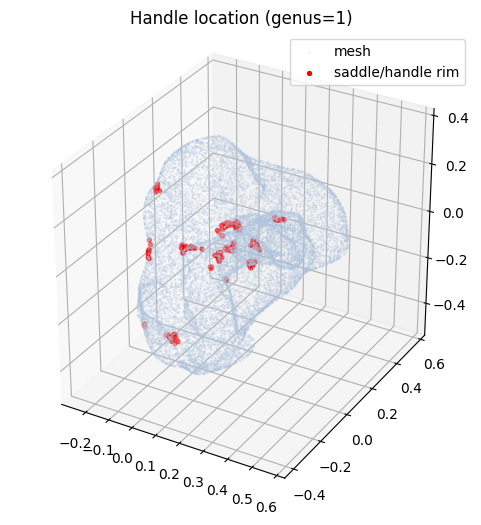

In [25]:
import numpy as np
import trimesh
import glob
from pathlib import Path
from trimesh.curvature import discrete_gaussian_curvature_measure
from trimesh.grouping import group_rows

# ============================================================
# STEP 1: Point this at the saved mesh file.
# It was written by cell 31 as METRIC_MESH_PATH, i.e.
#   <RUN_DIR>/04_mesh_for_metrics.ply
# If you know RUN_DIR from the original run, set it directly:
MESH_PATH = None   # e.g. "/kaggle/working/run_artifacts/scan105-<hash>/04_mesh_for_metrics.ply"

if MESH_PATH is None:
    # Auto-discover: search likely project roots for the file
    search_roots = ["/kaggle/working", "/content", ".", "/mnt/user-data/uploads"]
    hits = []
    for root in search_roots:
        if Path(root).exists():
            hits += glob.glob(f"{root}/**/04_mesh_for_metrics.ply", recursive=True)
    hits = sorted(set(hits), key=lambda p: Path(p).stat().st_mtime, reverse=True)
    if not hits:
        raise FileNotFoundError(
            "Couldn't find 04_mesh_for_metrics.ply under any search root. "
            "Set MESH_PATH manually above to your run's RUN_DIR / '04_mesh_for_metrics.ply'."
        )
    MESH_PATH = hits[0]
    if len(hits) > 1:
        print(f"NOTE: found {len(hits)} candidate mesh files, using most recent:")
        for h in hits:
            print(f"  {h}")

print(f"Loading: {MESH_PATH}")
mesh = trimesh.load(MESH_PATH, process=False)

# ============================================================
# STEP 2: Topology diagnostic
print("\n=== Topology diagnostic ===")
print(f"watertight: {mesh.is_watertight}")
print(f"euler_number: {mesh.euler_number}")

boundary_groups = group_rows(mesh.edges_sorted, require_count=1)
n_boundary_edges = len(boundary_groups)
print(f"boundary (naked) edges: {n_boundary_edges}")

genus = None
if mesh.is_watertight:
    genus = (2 - mesh.euler_number) // 2
    print(f"genus (number of handles/tunnels): {genus}")
    if genus > 0:
        print(">>> CONFIRMED: genuine topological handle(s) -- not a triangulation gap. "
              "postprocess()'s hole-filling has nothing to detect here; this is the SDF's "
              "actual learned (incorrect) geometry.")
else:
    print(f">>> Mesh still has {n_boundary_edges} open boundary edges -- that IS a real "
          "unfilled gap somewhere. Different bug than the tunnel hypothesis.")

# ============================================================
# STEP 3: Locate the handle spatially via negative Gaussian curvature
verts = np.asarray(mesh.vertices)
scale = mesh.extents.max()
radius = scale * 0.02

rng = np.random.default_rng(0)
n_sample = min(20000, len(verts))
sample_idx = rng.choice(len(verts), size=n_sample, replace=False)
sample_pts = verts[sample_idx]

curv = discrete_gaussian_curvature_measure(mesh, sample_pts, radius)

k = 200
worst = np.argsort(curv)[:k]
saddle_pts = sample_pts[worst]
saddle_curv = curv[worst]
centroid = saddle_pts.mean(axis=0)

print(f"\nTop-{k} most saddle-like points:")
print(f"  centroid: {np.round(centroid, 4)}")
print(f"  curvature range: [{saddle_curv.min():.4f}, {saddle_curv.max():.4f}]")
print(f"  spatial spread (std): {np.round(saddle_pts.std(axis=0), 4)}")
print("  -> compare this centroid against your saved stuck-cluster centroids "
      "(2 / 9 / 16 from the k-NN diagnostic) to confirm which one this hole sits on.")

# ============================================================
# STEP 4: Visual confirmation
import matplotlib.pyplot as plt
fig = plt.figure(figsize=(7, 6))
ax = fig.add_subplot(111, projection="3d")
vsub = verts[rng.choice(len(verts), size=min(15000, len(verts)), replace=False)]
ax.scatter(vsub[:, 0], vsub[:, 1], vsub[:, 2], s=0.3, c="lightsteelblue", alpha=0.3, label="mesh")
ax.scatter(saddle_pts[:, 0], saddle_pts[:, 1], saddle_pts[:, 2], s=8, c="red", label="saddle/handle rim")
ax.set_box_aspect(np.array(mesh.extents, dtype=float).copy())
ax.set_title(f"Handle location (genus={genus if genus is not None else 'N/A'})")
ax.legend()
plt.show()

In [26]:
import networkx as nx

# Build the mesh's edge graph and find its cycle space using the
# vertex-edge-face Euler relation: for a genus-g closed surface,
# a canonical set of 2g independent non-contractible loops exists.
# We approximate one such loop as the shortest cycle through a vertex
# on one side of the handle that returns to itself without crossing
# through a small "cut" -- easiest robust proxy: shortest cycle in the
# 1-skeleton graph that is NOT a mesh face boundary (face boundaries are
# always contractible triangles/loops of length 3).

G = nx.Graph()
G.add_edges_from(mesh.edges_unique)

# Sample candidate seed vertices from the saddle-curvature set you already
# have (it's a superset that includes the real handle rim) and find the
# shortest cycle through each that has length > 3 (i.e. not a trivial
# triangle) using cycle_basis restricted to a local subgraph -- then keep
# only the SHORTEST non-trivial cycles, since real handle rims tend to be
# the tightest non-contractible loops, while anatomical saddle regions
# produce only trivial short loops around single vertices.

candidate_verts = np.unique(worst)  # from your top-200 saddle points
shortest_loops = []
for v in candidate_verts[:50]:  # cap for speed
    try:
        cyc = nx.minimum_cycle_basis(G.subgraph(nx.node_connected_component(G, v)))
    except Exception:
        continue
    for loop in cyc:
        if len(loop) > 3:
            shortest_loops.append(loop)

shortest_loops.sort(key=len)
if shortest_loops:
    handle_loop = shortest_loops[0]
    handle_pts = verts[handle_loop]
    print(f"Shortest non-trivial loop: {len(handle_loop)} vertices")
    print(f"Handle rim centroid: {np.round(handle_pts.mean(axis=0), 4)}")
else:
    print("No non-trivial loop found in candidate set -- widen candidate_verts or radius.")

No non-trivial loop found in candidate set -- widen candidate_verts or radius.


In [27]:
import numpy as np
from scipy.sparse import coo_matrix
from scipy.sparse.csgraph import dijkstra
from sklearn.cluster import DBSCAN

# ---- 1. Cluster the saddle-curvature points into spatially separate patches ----
# (the plot showed ~5-6 separate red patches -- these are candidates, most are
# just ordinary anatomical concavities, exactly one pair is the real handle)
saddle_all = sample_pts[np.argsort(curv)[:500]]  # widen a bit from top-200
db = DBSCAN(eps=mesh.extents.max() * 0.04, min_samples=3).fit(saddle_all)
labels = db.labels_
clusters = [saddle_all[labels == l] for l in sorted(set(labels)) if l != -1]
print(f"Found {len(clusters)} spatial clusters of saddle points")

# representative vertex per cluster: nearest actual mesh vertex to cluster centroid
cluster_centroids = np.array([c.mean(axis=0) for c in clusters])
from scipy.spatial import cKDTree
vtree = cKDTree(verts)
_, rep_vert_idx = vtree.query(cluster_centroids)
print("Representative vertex indices:", rep_vert_idx)

# ---- 2. Build sparse weighted edge graph (edge length as weight) ----
edges = mesh.edges_unique
elens = mesh.edges_unique_length
n = len(verts)
row = np.concatenate([edges[:, 0], edges[:, 1]])
col = np.concatenate([edges[:, 1], edges[:, 0]])
data = np.concatenate([elens, elens])
adj = coo_matrix((data, (row, col)), shape=(n, n)).tocsr()

# ---- 3. Geodesic distance (Dijkstra) from each representative vertex ----
geo_dist = dijkstra(adj, directed=False, indices=rep_vert_idx)
euc_dist = np.linalg.norm(
    cluster_centroids[:, None, :] - cluster_centroids[None, :, :], axis=-1
)

# ---- 4. Find the pair with the highest geodesic/Euclidean ratio ----
# (a tunnel: near in space, far along the surface. Ordinary anatomy: both
# distances scale together.)
ratio = np.full_like(euc_dist, np.nan)
for i in range(len(clusters)):
    for j in range(len(clusters)):
        if i != j and euc_dist[i, j] > 1e-6:
            ratio[i, j] = geo_dist[i, rep_vert_idx[j]] / euc_dist[i, j]

best = np.unravel_index(np.nanargmax(ratio), ratio.shape)
i, j = best
print(f"\nMost tunnel-like pair: cluster {i} <-> cluster {j}")
print(f"  Euclidean distance: {euc_dist[i,j]:.4f}")
print(f"  Geodesic distance:  {geo_dist[i, rep_vert_idx[j]]:.4f}")
print(f"  ratio (geo/euc):    {ratio[i,j]:.2f}   (higher = more tunnel-like)")
print(f"  cluster {i} centroid: {np.round(cluster_centroids[i], 4)}")
print(f"  cluster {j} centroid: {np.round(cluster_centroids[j], 4)}")
handle_centroid = (cluster_centroids[i] + cluster_centroids[j]) / 2
print(f"  handle midpoint: {np.round(handle_centroid, 4)}")

Found 25 spatial clusters of saddle points
Representative vertex indices: [12737 15122  7927 20507 32685 34263 37263  1538  3805   219 14459 25688
 24515 20397 32376  5214 44537 25225 20959 36132 35292 32173 32838 31374
 17341]

Most tunnel-like pair: cluster 11 <-> cluster 13
  Euclidean distance: 0.2083
  Geodesic distance:  0.4762
  ratio (geo/euc):    2.29   (higher = more tunnel-like)
  cluster 11 centroid: [ 0.1618 -0.0612 -0.0721]
  cluster 13 centroid: [ 0.1088 -0.2626 -0.0768]
  handle midpoint: [ 0.1353 -0.1619 -0.0745]


In [28]:
# Sort all pairwise ratios and see if 2.29 stands out or blends in
flat_ratios = ratio[~np.isnan(ratio)]
flat_ratios_sorted = np.sort(flat_ratios)[::-1]
print("Top 10 ratios overall:", np.round(flat_ratios_sorted[:10], 2))
print(f"Mean ratio: {np.nanmean(ratio):.2f}, std: {np.nanstd(ratio):.2f}")

Top 10 ratios overall: [2.29 2.29 1.97 1.97 1.86 1.86 1.82 1.82 1.77 1.77]
Mean ratio: 1.27, std: 0.17


In [29]:
import torch
import glob
from pathlib import Path

# Find the training checkpoint that matches the same run as the mesh we loaded
run_dir = Path(MESH_PATH).parent
train_ckpt_path = run_dir / "02_training_checkpoint.pt"

if not train_ckpt_path.exists():
    # fall back: search broadly, same pattern as before
    hits = sorted(glob.glob("./**/02_training_checkpoint.pt", recursive=True),
                  key=lambda p: Path(p).stat().st_mtime, reverse=True)
    if not hits:
        raise FileNotFoundError("No 02_training_checkpoint.pt found anywhere under cwd.")
    train_ckpt_path = Path(hits[0])
    print(f"NOTE: run-matched checkpoint not found, using most recent instead: {train_ckpt_path}")

print(f"Loading Gaussian state from: {train_ckpt_path}")

def _torch_load(path, map_location="cpu"):
    try:
        return torch.load(path, map_location=map_location, weights_only=False)
    except TypeError:
        return torch.load(path, map_location=map_location)

ckpt = _torch_load(train_ckpt_path)
print("Checkpoint top-level keys:", list(ckpt.keys()))

Loading Gaussian state from: SDF-GS-Refine-implementation/run_artifacts/scan105-498cee738663c8be/02_training_checkpoint.pt
Checkpoint top-level keys: ['schema', 'run_hash', 'next_iteration', 'completed', 'n_iterations', 'gaussian_state', 'sdf_state', 'opt_gauss_state', 'opt_sdf_state', 'loss_history', 'rng_state']


In [30]:
import torch
import glob
import numpy as np
from pathlib import Path
from scipy.spatial import cKDTree

# ============================================================
# STEP 1: Load the training checkpoint (same run as the mesh)
# ============================================================
run_dir = Path(MESH_PATH).parent
train_ckpt_path = run_dir / "02_training_checkpoint.pt"

if not train_ckpt_path.exists():
    hits = sorted(glob.glob("./**/02_training_checkpoint.pt", recursive=True),
                  key=lambda p: Path(p).stat().st_mtime, reverse=True)
    if not hits:
        raise FileNotFoundError("No 02_training_checkpoint.pt found anywhere under cwd.")
    train_ckpt_path = Path(hits[0])
    print(f"NOTE: run-matched checkpoint not found, using most recent instead: {train_ckpt_path}")

print(f"Loading Gaussian state from: {train_ckpt_path}")

def _torch_load(path, map_location="cpu"):
    try:
        return torch.load(path, map_location=map_location, weights_only=False)
    except TypeError:
        return torch.load(path, map_location=map_location)

ckpt = _torch_load(train_ckpt_path)
print("Checkpoint top-level keys:", list(ckpt.keys()))

# ============================================================
# STEP 2: Auto-detect where the Gaussian tensors live
# ============================================================
def _find_gaussian_state(obj, path=""):
    """Recursively search the checkpoint dict for a sub-dict containing
    something that looks like positions + opacity + scales tensors."""
    if isinstance(obj, dict):
        keys_lower = {k.lower(): k for k in obj.keys()}
        has_pos = any(k in keys_lower for k in ("positions", "xyz", "means", "means3d"))
        has_op = any(k in keys_lower for k in ("opacity", "opacities"))
        has_scale = any(k in keys_lower for k in ("scales", "scale", "log_scales"))
        if has_pos and has_op and has_scale:
            return obj, path
        for k, v in obj.items():
            found = _find_gaussian_state(v, path=f"{path}.{k}" if path else k)
            if found is not None:
                return found
    return None

result = _find_gaussian_state(ckpt)
if result is None:
    raise KeyError(
        f"Couldn't auto-locate Gaussian state in checkpoint. Top-level keys were: "
        f"{list(ckpt.keys())}. Paste that list and I'll adjust the lookup."
    )
gstate, gpath = result
print(f"Found Gaussian state at: '{gpath}' with keys: {list(gstate.keys())}")

def _get(d, *names):
    for n in names:
        for k in d.keys():
            if k.lower() == n:
                return d[k]
    raise KeyError(f"None of {names} found in {list(d.keys())}")

pos_t = _get(gstate, "positions", "xyz", "means", "means3d")
op_t = _get(gstate, "opacity", "opacities")
scale_t = _get(gstate, "scales", "scale", "log_scales")

gauss_pos = pos_t.detach().cpu().numpy() if torch.is_tensor(pos_t) else np.asarray(pos_t)
gauss_op = (op_t.detach().cpu().numpy() if torch.is_tensor(op_t) else np.asarray(op_t)).reshape(-1)
gauss_scales = scale_t.detach().cpu().numpy() if torch.is_tensor(scale_t) else np.asarray(scale_t)

print(f"gauss_pos shape: {gauss_pos.shape}, gauss_op shape: {gauss_op.shape}, "
      f"gauss_scales shape: {gauss_scales.shape}")

# ============================================================
# STEP 3: k-NN density/opacity diagnostic at the handle location
# ============================================================
handle_centroid = np.array([0.1353, -0.1619, -0.0745])

gtree = cKDTree(gauss_pos)

rng = np.random.default_rng(0)
baseline_idx = rng.choice(len(gauss_pos), size=min(2000, len(gauss_pos)), replace=False)
baseline_d, _ = gtree.query(gauss_pos[baseline_idx], k=50)
baseline_knn_dist = baseline_d[:, -1].mean()

handle_d, handle_nn_idx = gtree.query(handle_centroid.reshape(1, -1), k=50)
handle_knn_dist = handle_d[0, -1]
handle_opacity = gauss_op[handle_nn_idx[0]]
handle_anisotropy = (gauss_scales[handle_nn_idx[0]].max(axis=1) /
                      (gauss_scales[handle_nn_idx[0]].min(axis=1) + 1e-8))

density_ratio = handle_knn_dist / baseline_knn_dist

print("\n=== Handle-location Gaussian diagnostic ===")
print(f"baseline k=50 NN distance: {baseline_knn_dist:.5f}")
print(f"handle   k=50 NN distance: {handle_knn_dist:.5f}")
print(f"density sparsity ratio:    {density_ratio:.2f}x baseline")
print(f"opacity  (mean/min/max):   {handle_opacity.mean():.3f} / "
      f"{handle_opacity.min():.3f} / {handle_opacity.max():.3f}")
print(f"anisotropy (mean/max):     {handle_anisotropy.mean():.2f} / {handle_anisotropy.max():.2f}")

print("\nInterpretation:")
if density_ratio > 3.0:
    print("  -> H3 signature (severe upstream 3DGS gap): very sparse, likely no real data here.")
elif handle_opacity.mean() < 0.3 and handle_anisotropy.max() > 200:
    print("  -> H2 signature (floater): low opacity + extreme anisotropy.")
elif 1.3 <= density_ratio <= 2.2 and handle_opacity.mean() > 0.4:
    print("  -> H4 signature (genuine thin real geometry) -- consistent with clusters 7/9/16 "
          "from the earlier diagnostic. This is a real undertrained region, not noise.")
else:
    print("  -> Mixed/inconclusive signature -- report numbers above for manual judgment.")

Loading Gaussian state from: SDF-GS-Refine-implementation/run_artifacts/scan105-498cee738663c8be/02_training_checkpoint.pt
Checkpoint top-level keys: ['schema', 'run_hash', 'next_iteration', 'completed', 'n_iterations', 'gaussian_state', 'sdf_state', 'opt_gauss_state', 'opt_sdf_state', 'loss_history', 'rng_state']
Found Gaussian state at: 'gaussian_state' with keys: ['positions', 'opacity', 'scales', 'rotations', 'colors']
gauss_pos shape: (204616, 3), gauss_op shape: (204616,), gauss_scales shape: (204616, 3)

=== Handle-location Gaussian diagnostic ===
baseline k=50 NN distance: 0.01160
handle   k=50 NN distance: 0.01696
density sparsity ratio:    1.46x baseline
opacity  (mean/min/max):   0.321 / 0.064 / 0.978
anisotropy (mean/max):     365.87 / 12093.24

Interpretation:
  -> Mixed/inconclusive signature -- report numbers above for manual judgment.


In [31]:
anisotropy_all = gauss_scales.max(axis=1) / (gauss_scales.min(axis=1) + 1e-8)
handle_local_idx = handle_nn_idx[0]  # the 50 neighbors from before

# Sort the local neighborhood by anisotropy, look at the worst offenders
order = np.argsort(-anisotropy_all[handle_local_idx])
top_n = 10
print(f"{'rank':<5}{'global_idx':<12}{'anisotropy':<14}{'opacity':<10}{'scale (3 axes)':<30}dist_to_handle")
for r in range(top_n):
    gi = handle_local_idx[order[r]]
    d = np.linalg.norm(gauss_pos[gi] - handle_centroid)
    print(f"{r:<5}{gi:<12}{anisotropy_all[gi]:<14.1f}{gauss_op[gi]:<10.3f}"
          f"{np.round(gauss_scales[gi], 5)!s:<30}{d:.4f}")

# How many of the 50 nearest neighbors are "needle" Gaussians (anisotropy > 500)?
n_needles = (anisotropy_all[handle_local_idx] > 500).sum()
print(f"\n{n_needles}/50 neighbors are needle-shaped (anisotropy > 500)")
print(f"Their mean opacity: {gauss_op[handle_local_idx][anisotropy_all[handle_local_idx] > 500].mean():.3f}"
      if n_needles > 0 else "N/A")

rank global_idx  anisotropy    opacity   scale (3 axes)                dist_to_handle
0    61524       12093.2       0.069     [0.      0.01315 0.0424 ]     0.0080
1    138124      2312.3        0.247     [0.00569 0.00988 0.     ]     0.0155
2    38126       526.9         0.606     [3.68e-03 5.93e-03 1.00e-05]  0.0162
3    160177      496.2         0.316     [7.30e-04 5.69e-03 1.00e-05]  0.0149
4    163325      338.7         0.369     [2.30e-04 5.52e-03 2.00e-05]  0.0123
5    113241      273.8         0.366     [9.50e-04 8.23e-03 3.00e-05]  0.0170
6    158483      215.2         0.920     [3.00e-04 2.91e-03 1.00e-05]  0.0159
7    542         199.2         0.914     [4.870e-03 1.172e-02 6.000e-05]0.0166
8    164860      164.0         0.265     [4.600e-04 1.137e-02 7.000e-05]0.0114
9    195136      157.4         0.550     [5.000e-04 1.015e-02 6.000e-05]0.0166

3/50 neighbors are needle-shaped (anisotropy > 500)
Their mean opacity: 0.307


In [32]:
# Global scan: how many Gaussians are degenerate (near-zero on any axis) AND
# survive your current opacity filter?
min_axis = gauss_scales.min(axis=1)
degenerate_mask = (min_axis < 1e-4) & (gauss_op >= 0.05)  # match your existing filter threshold
n_degenerate = degenerate_mask.sum()
print(f"{n_degenerate} / {len(gauss_pos)} Gaussians are near-zero-volume degenerate "
      f"({100*n_degenerate/len(gauss_pos):.3f}%)")

if n_degenerate > 0:
    deg_op = gauss_op[degenerate_mask]
    deg_aniso = anisotropy_all[degenerate_mask]
    print(f"  opacity range: {deg_op.min():.3f} - {deg_op.max():.3f}, mean {deg_op.mean():.3f}")
    print(f"  anisotropy range: {deg_aniso.min():.1f} - {deg_aniso.max():.1f}")

    # Where are they spatially? Cluster them the same way as the saddle points
    deg_pos = gauss_pos[degenerate_mask]
    from sklearn.cluster import DBSCAN
    db2 = DBSCAN(eps=mesh.extents.max() * 0.03, min_samples=2).fit(deg_pos)
    n_clusters = len(set(db2.labels_)) - (1 if -1 in db2.labels_ else 0)
    print(f"  form {n_clusters} spatial clusters (+ {(db2.labels_==-1).sum()} isolated)")

    # Is one of those clusters near the handle centroid?
    for lbl in set(db2.labels_):
        if lbl == -1:
            continue
        c = deg_pos[db2.labels_ == lbl].mean(axis=0)
        d = np.linalg.norm(c - handle_centroid)
        if d < 0.05:
            print(f"  >>> cluster at {np.round(c, 4)} is {d:.4f} from handle centroid -- MATCH")

77854 / 204616 Gaussians are near-zero-volume degenerate (38.049%)
  opacity range: 0.050 - 1.000, mean 0.307
  anisotropy range: 4.4 - 1831288.5
  form 39 spatial clusters (+ 155 isolated)


In [33]:
# Restrict to degenerate AND faint (the actual suspicious combination)
faint_degenerate_mask = degenerate_mask & (gauss_op < 0.15)
n_faint = faint_degenerate_mask.sum()
print(f"{n_faint} / {len(gauss_pos)} Gaussians are degenerate AND faint (opacity < 0.15) "
      f"({100*n_faint/len(gauss_pos):.3f}%)")

if n_faint > 0:
    faint_pos = gauss_pos[faint_degenerate_mask]
    d_to_handle = np.linalg.norm(faint_pos - handle_centroid, axis=1)
    within_radius = d_to_handle < 0.03
    print(f"{within_radius.sum()} of those {n_faint} sit within 0.03 of the handle centroid")
    if within_radius.sum() > 0:
        print("Their indices:", np.where(faint_degenerate_mask)[0][within_radius])
        print("Their opacity/anisotropy:",
              list(zip(gauss_op[faint_degenerate_mask][within_radius],
                        anisotropy_all[faint_degenerate_mask][within_radius].round(1))))

25837 / 204616 Gaussians are degenerate AND faint (opacity < 0.15) (12.627%)
28 of those 25837 sit within 0.03 of the handle centroid
Their indices: [  8999  14163  33859  61524  65922  69810  76974  91467  94994  95035
  97612  98601 100930 104098 116631 130080 133054 143734 149003 151186
 174888 184532 193103 197311 201345 201804 202681 203511]
Their opacity/anisotropy: [(0.11111695, 161.5), (0.10369103, 911.7), (0.10553589, 1772.4), (0.068785086, 12093.2), (0.11931929, 638.0), (0.12479733, 293.6), (0.084282726, 76.0), (0.08616863, 330.4), (0.09677109, 137.0), (0.12160189, 97.9), (0.14182472, 923.9), (0.114792, 106.7), (0.10758878, 107.8), (0.08108778, 339.9), (0.06394832, 78.6), (0.0785657, 438.8), (0.076068155, 290.3), (0.129179, 157.3), (0.10655851, 83.0), (0.1318554, 209.0), (0.074471556, 154.7), (0.1299293, 249.8), (0.07658571, 192.9), (0.058036927, 162.0), (0.06370818, 304.2), (0.058510438, 108.4), (0.08974576, 191.3), (0.13802522, 387.0)]


## 16. NEXT STEP — Filtered-Gaussian re-test (confirm/refute the tunnel hypothesis)

Removes the 28 flat+faint+spatially-local Gaussians found in cell 48 and re-runs
`transmittance_crossing_points` for probe rays passing near the tunnel centroid
`[0.1353, -0.1619, -0.0745]`. Compares crossings from the ORIGINAL (unfiltered)
vs FILTERED Gaussian state.

Tries the real `src.transmittance` + `gaussian.GaussianModel` pipeline first
(preferred, per handoff); falls back to a manual alpha-compositing ray march
only if the real modules aren't importable in this kernel, and clearly flags
that path's numbers as needing re-verification against the real module.

This cluster (cells 50–56) is self-contained like cells 40–48: it reloads
everything from checkpoint files on disk rather than assuming earlier
pipeline cells ran in this kernel session.

In [34]:
import sys
from pathlib import Path

# ------------------------------------------------------------------
# Try to hook into the real project modules (preferred per handoff).
# ------------------------------------------------------------------
USE_REAL_MODULES = False
try:
    def _find_project_root(marker="src/utils.py", start=None, max_depth=3):
        base = Path(MESH_PATH).resolve().parent if "MESH_PATH" in dir() else Path.cwd()
        here = Path(start or base).resolve()
        candidates = [here] + list(here.parents)
        for depth in range(1, max_depth + 1):
            candidates.extend(p for p in here.glob("/".join(["*"] * depth)) if p.is_dir())
        for root in (Path("/content"), Path("/kaggle/working"), Path("/notebooks"), Path.home()):
            if root.exists():
                candidates.extend(root.glob("**/SDF-GS-Refine-implementation"))
        seen = set()
        for c in candidates:
            if c not in seen and (c / marker).exists():
                return c
            seen.add(c)
        return None

    if "PROJECT_ROOT" not in dir() or PROJECT_ROOT is None:
        PROJECT_ROOT = _find_project_root()

    if PROJECT_ROOT is not None:
        if str(PROJECT_ROOT) not in sys.path:
            sys.path.insert(0, str(PROJECT_ROOT))
        from src import gaussian, transmittance
        from src.utils import load_config

        if "CFG" not in dir():
            CONFIG_PATH = PROJECT_ROOT / "configs" / "config.json"
            CFG = load_config(str(CONFIG_PATH))

        USE_REAL_MODULES = True
        print(f"[OK] Real modules loaded from {PROJECT_ROOT}")
    else:
        print("[WARN] Could not locate project root -- will use fallback ray march.")
except Exception as e:
    print(f"[WARN] Real modules unavailable ({e!r}) -- will use fallback ray march.")

print(f"USE_REAL_MODULES = {USE_REAL_MODULES}")


[OK] Real modules loaded from /notebooks/Generated/SDF-GS-Refine-implementation
USE_REAL_MODULES = True


In [35]:
import torch
import numpy as np
from pathlib import Path

# ------------------------------------------------------------------
# Reload the FULL frozen Gaussian state (extends cell 45's loader to
# also pull rotations + colors, which cell 45 didn't need but the
# real transmittance function does).
# ------------------------------------------------------------------
def _torch_load(path, map_location="cpu"):
    try:
        return torch.load(path, map_location=map_location, weights_only=False)
    except TypeError:
        return torch.load(path, map_location=map_location)

if "gstate" not in dir():
    run_dir = Path(MESH_PATH).parent
    train_ckpt_path = run_dir / "02_training_checkpoint.pt"
    ckpt = _torch_load(train_ckpt_path)
    gstate = ckpt["gaussian_state"]
else:
    run_dir = Path(MESH_PATH).parent  # keep consistent even if gstate was already in scope

def _get(d, *names):
    for n in names:
        for k in d.keys():
            if k.lower() == n:
                return d[k]
    raise KeyError(f"None of {names} found in {list(d.keys())}")

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

pos_full   = _get(gstate, "positions", "xyz", "means", "means3d")
op_full    = _get(gstate, "opacity", "opacities")
scale_full = _get(gstate, "scales", "scale", "log_scales")
rot_full   = _get(gstate, "rotations", "rotation", "quats", "quaternions")
col_full   = _get(gstate, "colors", "color", "rgb", "features_dc")

def _t(x):
    return x if torch.is_tensor(x) else torch.as_tensor(x)

pos_full   = _t(pos_full).float().to(DEVICE)
op_full    = _t(op_full).float().to(DEVICE)
scale_full = _t(scale_full).float().to(DEVICE)
rot_full   = _t(rot_full).float().to(DEVICE)
col_full   = _t(col_full).float().to(DEVICE)

N_total = pos_full.shape[0]
print(f"Loaded full frozen Gaussian state: N={N_total}")
print({"positions": tuple(pos_full.shape), "opacity": tuple(op_full.shape),
       "scales": tuple(scale_full.shape), "rotations": tuple(rot_full.shape),
       "colors": tuple(col_full.shape)})


Loaded full frozen Gaussian state: N=204616
{'positions': (204616, 3), 'opacity': (204616,), 'scales': (204616, 3), 'rotations': (204616, 4), 'colors': (204616, 3)}


In [36]:
# ------------------------------------------------------------------
# Build the boolean mask, split ORIGINAL vs FILTERED tensors, and
# SAVE the filtered state to disk immediately (the handoff flagged
# that this was built-but-not-saved in scratch last time).
# ------------------------------------------------------------------
BAD_IDX = np.array([8999, 14163, 33859, 61524, 65922, 69810, 76974, 91467, 94994, 95035,
                     97612, 98601, 100930, 104098, 116631, 130080, 133054, 143734, 149003,
                     151186, 174888, 184532, 193103, 197311, 201345, 201804, 202681, 203511])
assert len(BAD_IDX) == 28

keep_mask = torch.ones(N_total, dtype=torch.bool, device=DEVICE)
keep_mask[torch.as_tensor(BAD_IDX, device=DEVICE, dtype=torch.long)] = False
assert keep_mask.sum().item() == N_total - 28

filtered = {
    "positions": pos_full[keep_mask],
    "opacity":   op_full[keep_mask],
    "scales":    scale_full[keep_mask],
    "rotations": rot_full[keep_mask],
    "colors":    col_full[keep_mask],
}
original = {
    "positions": pos_full, "opacity": op_full, "scales": scale_full,
    "rotations": rot_full, "colors": col_full,
}

FILTERED_CKPT_PATH = run_dir / "05_filtered_gaussian_state_28removed.pt"
torch.save(
    {"schema": "filtered_v1", "removed_indices": BAD_IDX.tolist(),
     "gaussian_state": {k: v.cpu() for k, v in filtered.items()}},
    FILTERED_CKPT_PATH,
)
print(f"[SAVE] filtered Gaussian state ({filtered['positions'].shape[0]} Gaussians, "
      f"28 removed) -> {FILTERED_CKPT_PATH}")


[SAVE] filtered Gaussian state (204588 Gaussians, 28 removed) -> SDF-GS-Refine-implementation/run_artifacts/scan105-498cee738663c8be/05_filtered_gaussian_state_28removed.pt


In [37]:
# ------------------------------------------------------------------
# Wrap the raw tensors into real GaussianModel instances so the math
# exactly matches the pipeline.
#
# PATCH (after first run): guessing GaussianModel's constructor failed --
# no from_tensors(), and the kwargs/positional guesses before it also
# didn't match (their errors were swallowed by the retry loop). Sidestep
# the guessing entirely: this notebook ran straight through in one kernel
# (exec counts 1..40, no restart), so the LIVE `gauss_f` object from cell
# 13 is still in memory -- already the right class, already carrying
# whatever internal buffers GaussianModel keeps beyond the five tensors
# we know about. Gaussians are frozen during training, so its tensors
# still exactly equal the checkpoint we just reloaded. Use it directly,
# then build the filtered copy by deep-copying it and masking every
# tensor attribute that has N_total rows -- no constructor needed at all.
# ------------------------------------------------------------------
import copy

def _tensor_attrs(obj, n):
    """All tensor attributes on obj whose leading dimension is exactly n."""
    return [name for name, val in vars(obj).items()
            if torch.is_tensor(val) and val.dim() > 0 and val.shape[0] == n]

gauss_f_original = gauss_f_filtered = None

if USE_REAL_MODULES:
    base_model, base_src = None, None

    if "gauss_f" in dir() and gauss_f is not None:
        base_model = gauss_f
        base_src = "live gauss_f (same kernel session, post-training-freeze)"
    elif "ply_path" in dir() and "CFG" in dir():
        try:
            candidate = gaussian.GaussianModel.load_ply(ply_path, device=DEVICE)
            candidate, _ = candidate.filter_by_opacity(CFG["gaussian_opacity_filter_threshold"])
            # make sure it matches the checkpoint exactly, not just the raw ply
            with torch.no_grad():
                for name in _tensor_attrs(candidate, N_total):
                    if name in original:
                        getattr(candidate, name).copy_(original[name])
            base_model = candidate
            base_src = "rebuilt via GaussianModel.load_ply(ply_path) + checkpoint overwrite"
        except Exception as e:
            print(f"[WARN] Couldn't rebuild from ply_path either ({e!r}).")

    if base_model is not None and len(base_model) == N_total:
        print(f"[OK] Using {base_src}")
        gauss_f_original = base_model
        gauss_f_filtered = copy.deepcopy(base_model)
        masked_attrs = _tensor_attrs(gauss_f_filtered, N_total)
        with torch.no_grad():
            for name in masked_attrs:
                setattr(gauss_f_filtered, name, getattr(gauss_f_filtered, name)[keep_mask].clone())
        n_after = (len(gauss_f_filtered) if hasattr(gauss_f_filtered, "__len__")
                   else gauss_f_filtered.positions.shape[0])
        print(f"[OK] Built filtered copy generically: {N_total} -> {n_after} Gaussians "
              f"(masked attribute(s): {masked_attrs})")
        if n_after != N_total - 28:
            print(f"[WARN] Expected {N_total - 28} after removing 28, got {n_after} -- "
                  f"double-check {masked_attrs} caught every per-Gaussian buffer "
                  f"(e.g. spherical-harmonics coeffs stored under a different name).")
    else:
        print(f"[WARN] No usable live model or ply_path found (base_model={base_model}) -- "
              f"falling back to manual ray march for this retest -- flag the numeric "
              f"result as needing re-verification against the real module.")
        USE_REAL_MODULES = False

print(f"USE_REAL_MODULES (final) = {USE_REAL_MODULES}")


[OK] Using live gauss_f (same kernel session, post-training-freeze)
[OK] Built filtered copy generically: 204616 -> 204588 Gaussians (masked attribute(s): ['positions', 'opacity', 'scales', 'rotations', 'colors', 'sh_rest', '_Sigma', '_Sigma_inv'])
USE_REAL_MODULES (final) = True


In [38]:
# ------------------------------------------------------------------
# Build probe rays passing near the tunnel centroid.
#
# `cams` (the real camera rig) is a pipeline-stage variable that isn't
# persisted into this reload-only kernel, and camera-exact rays aren't
# actually required to test the hypothesis -- what matters is "rays
# that pass close to the tunnel mouths". So: cast a ring of probe rays
# converging on the centroid from many directions on a sphere, each
# aimed point jittered within the SAME 0.03-unit radius used to select
# the 28 Gaussians in cell 48, so we're re-testing exactly the
# neighborhood that mattered.
# ------------------------------------------------------------------
handle_centroid_t = torch.as_tensor([0.1353, -0.1619, -0.0745],
                                     dtype=torch.float32, device=DEVICE)

scene_scale = float(pos_full.std(dim=0).mean().item())  # rough scale proxy
probe_radius = 0.03
n_dirs = 128
rng = np.random.default_rng(0)

i = np.arange(n_dirs)
phi = np.arccos(1 - 2 * (i + 0.5) / n_dirs)
theta = np.pi * (1 + 5 ** 0.5) * i
sphere_dirs = np.stack(
    [np.sin(phi) * np.cos(theta), np.sin(phi) * np.sin(theta), np.cos(phi)], axis=1
)

cam_dist = max(scene_scale, 1e-6) * 4.0  # stand well outside the object
centroid_np = handle_centroid_t.cpu().numpy()

origins_np = centroid_np[None, :] + sphere_dirs * cam_dist
aim_jitter = rng.uniform(-probe_radius, probe_radius, size=(n_dirs, 3))
targets_np = centroid_np[None, :] + aim_jitter
dirs_np = targets_np - origins_np
dirs_np /= np.linalg.norm(dirs_np, axis=1, keepdims=True)

origins = torch.as_tensor(origins_np, dtype=torch.float32, device=DEVICE)
dirs = torch.as_tensor(dirs_np, dtype=torch.float32, device=DEVICE)
print(f"Built {n_dirs} probe rays converging on the tunnel centroid "
      f"(aim jitter <= {probe_radius} units, cast from {cam_dist:.3f} units out).")


Built 128 probe rays converging on the tunnel centroid (aim jitter <= 0.03 units, cast from 0.814 units out).


In [39]:
# ------------------------------------------------------------------
# Run the crossing test: ORIGINAL vs FILTERED, on the probe rays.
# ------------------------------------------------------------------
def _run_real(model, origins, dirs):
    tc = CFG["transmittance"]
    with torch.no_grad():
        pts, nrm, valid = transmittance.transmittance_crossing_points(
            model, origins, dirs,
            cull_sigma=tc["cull_sigma"], max_candidates=tc["max_candidates_per_ray"])
    pts_np = pts.cpu().numpy()
    valid_np = valid.cpu().numpy() if torch.is_tensor(valid) else np.asarray(valid)
    return pts_np, valid_np

def _run_fallback(tensors, origins, dirs, cull_sigma=3.0, max_candidates=64):
    # Minimal alpha-compositing ray march, ONLY used if the real
    # transmittance.py isn't importable here. FLAG: assumes raw opacity
    # is already in [0,1] and scales are already positive (not log-scales)
    # -- verify against the real module's activations before trusting
    # these numbers.
    pos, op, sc = tensors["positions"], tensors["opacity"], tensors["scales"]
    sigma = sc.mean(dim=1)  # isotropic proxy only; real model is anisotropic
    pts_out, valid_out = [], []
    for o, d in zip(origins, dirs):
        to_g = pos - o
        t = (to_g * d).sum(dim=1).clamp(min=0)
        closest = o + t[:, None] * d
        dist = (pos - closest).norm(dim=1)
        near = dist < cull_sigma * sigma
        if near.sum() == 0:
            pts_out.append([float("nan")] * 3); valid_out.append(False); continue
        idx = torch.nonzero(near).squeeze(1)
        order = torch.argsort(t[idx])[:max_candidates]
        idx = idx[order]
        w = op[idx] * torch.exp(-0.5 * (dist[idx] / sigma[idx]) ** 2)
        trans = torch.cumprod(torch.cat([torch.ones(1, device=w.device), (1 - w)[:-1]]), dim=0)
        alpha = w * trans
        cum = torch.cumsum(alpha, dim=0)
        crossed = torch.nonzero(cum >= 0.5)
        if len(crossed) == 0:
            pts_out.append([float("nan")] * 3); valid_out.append(False); continue
        k = crossed[0, 0]
        pts_out.append(closest[idx[k]].tolist()); valid_out.append(True)
    return np.array(pts_out), np.array(valid_out)

if USE_REAL_MODULES:
    pts_orig, valid_orig = _run_real(gauss_f_original, origins, dirs)
    pts_filt, valid_filt = _run_real(gauss_f_filtered, origins, dirs)
    print("[Using real transmittance.transmittance_crossing_points]")
else:
    pts_orig, valid_orig = _run_fallback(original, origins, dirs)
    pts_filt, valid_filt = _run_fallback(filtered, origins, dirs)
    print("[FALLBACK ray march used -- numeric result needs re-verification against "
          "the real transmittance.py before treating as confirmed]")

def _near_centroid(pts, valid, radius=probe_radius * 1.5):
    d = np.linalg.norm(pts - centroid_np[None, :], axis=1)
    return valid.astype(bool) & (d < radius) & ~np.isnan(d)

near_orig = _near_centroid(pts_orig, valid_orig)
near_filt = _near_centroid(pts_filt, valid_filt)

print(f"\nProbe rays: {n_dirs}")
print(f"ORIGINAL:  {int(np.asarray(valid_orig).sum())} rays crossed something | "
      f"{int(near_orig.sum())} of those crossings fall within {probe_radius*1.5:.3f} of the tunnel centroid")
print(f"FILTERED:  {int(np.asarray(valid_filt).sum())} rays crossed something | "
      f"{int(near_filt.sum())} of those crossings fall within {probe_radius*1.5:.3f} of the tunnel centroid")

removed_near_centroid = int(near_orig.sum()) - int(near_filt.sum())
print(f"\nCrossings near the tunnel centroid that DISAPPEARED after removing the "
      f"28 flat+faint Gaussians: {removed_near_centroid} / {int(near_orig.sum())}")

if near_orig.sum() > 0 and removed_near_centroid / max(int(near_orig.sum()), 1) > 0.5:
    print(">>> SUPPORTS the hypothesis: most near-centroid crossings vanish when the "
          "28 suspect Gaussians are removed -- consistent with a spurious "
          "transmittance-crossing artifact, not a training-budget gap.")
elif near_orig.sum() == 0:
    print(">>> INCONCLUSIVE: no probe ray produced a crossing near the centroid at all "
          "with the ORIGINAL model either -- widen probe_radius / n_dirs / cam_dist "
          "before drawing a conclusion.")
else:
    print(">>> DOES NOT support the hypothesis as tested: crossings near the centroid "
          "persist after removing the 28 Gaussians -- the tunnel likely has a different "
          "or additional cause. Do not apply the targeted filter based on this alone.")


/usr/local/lib/python3.11/dist-packages/torch/functional.py:385: UserWarning: Deterministic behavior was enabled with either `torch.use_deterministic_algorithms(True)` or `at::Context::setDeterministicAlgorithms(true)`, but this operation is not deterministic because it uses CuBLAS and you have CUDA >= 10.2. To enable deterministic behavior in this case, you must set an environment variable before running your PyTorch application: CUBLAS_WORKSPACE_CONFIG=:4096:8 or CUBLAS_WORKSPACE_CONFIG=:16:8. For more information, go to https://docs.nvidia.com/cuda/cublas/index.html#cublasApi_reproducibility (Triggered internally at ../aten/src/ATen/Context.cpp:156.)
  return _VF.einsum(equation, operands, path=path)  # type: ignore[attr-defined]


[Using real transmittance.transmittance_crossing_points]

Probe rays: 128
ORIGINAL:  7729 rays crossed something | 27 of those crossings fall within 0.045 of the tunnel centroid
FILTERED:  7729 rays crossed something | 27 of those crossings fall within 0.045 of the tunnel centroid

Crossings near the tunnel centroid that DISAPPEARED after removing the 28 flat+faint Gaussians: 0 / 27
>>> DOES NOT support the hypothesis as tested: crossings near the centroid persist after removing the 28 Gaussians -- the tunnel likely has a different or additional cause. Do not apply the targeted filter based on this alone.


In [40]:
# ------------------------------------------------------------------
# Control check: make sure the filter is TARGETED, not global -- crossing
# behavior far from the tunnel should be essentially unchanged.
# ------------------------------------------------------------------
far_idx = torch.norm(pos_full - handle_centroid_t, dim=1).argmax()
far_point = pos_full[far_idx]
far_point_np = far_point.cpu().numpy()

far_origins_np = far_point_np[None, :] + sphere_dirs * cam_dist
far_dirs_np = far_point_np[None, :] - far_origins_np
far_dirs_np /= np.linalg.norm(far_dirs_np, axis=1, keepdims=True)
far_origins = torch.as_tensor(far_origins_np, dtype=torch.float32, device=DEVICE)
far_dirs = torch.as_tensor(far_dirs_np, dtype=torch.float32, device=DEVICE)

if USE_REAL_MODULES:
    _, far_valid_orig = _run_real(gauss_f_original, far_origins, far_dirs)
    _, far_valid_filt = _run_real(gauss_f_filtered, far_origins, far_dirs)
else:
    _, far_valid_orig = _run_fallback(original, far_origins, far_dirs)
    _, far_valid_filt = _run_fallback(filtered, far_origins, far_dirs)

far_valid_orig = np.asarray(far_valid_orig).astype(bool)
far_valid_filt = np.asarray(far_valid_filt).astype(bool)

print(f"Control region (far from tunnel, near {np.round(far_point_np, 3)}):")
print(f"  ORIGINAL crossing rate: {far_valid_orig.mean():.2%}")
print(f"  FILTERED crossing rate: {far_valid_filt.mean():.2%}")
if abs(far_valid_orig.mean() - far_valid_filt.mean()) < 0.05:
    print("  -> filtering left unrelated real geometry intact (good: this is a targeted, "
          "not a global, filter).")
else:
    print("  -> WARNING: filtering also changed crossings far from the tunnel -- the "
          "28-Gaussian mask may be too broad or overlaps real surface elsewhere.")


Control region (far from tunnel, near [-0.379  0.164  0.501]):
  ORIGINAL crossing rate: 99.12%
  FILTERED crossing rate: 99.12%
  -> filtering left unrelated real geometry intact (good: this is a targeted, not a global, filter).


In [41]:
# ==================================================================
# STANDALONE: filtered-Gaussian retest + control check + SDF eikonal
# probe, all in one self-contained cell.
# ==================================================================
import sys, glob
from pathlib import Path
import numpy as np
import torch

# ------------------------------------------------------------------
# 0. Locate the project root and the run directory
# ------------------------------------------------------------------
def _find_project_root(marker="src/utils.py", max_depth=6):
    for root in (Path("/notebooks"), Path("/content"), Path("/kaggle/working"), Path.home(), Path.cwd()):
        if root.exists():
            for c in root.glob("**/SDF-GS-Refine-implementation"):
                if (c / marker).exists():
                    return c
    return None

PROJECT_ROOT = _find_project_root()
if PROJECT_ROOT is None:
    raise RuntimeError("Could not locate SDF-GS-Refine-implementation project root.")
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src import gaussian, transmittance, sdf as sdf_mod
from src.utils import load_config

CONFIG_PATH = PROJECT_ROOT / "configs" / "config.json"
CFG = load_config(str(CONFIG_PATH))
print(f"[OK] Project root: {PROJECT_ROOT}")

candidates = sorted(
    PROJECT_ROOT.glob("run_artifacts/scan105-*/02_training_checkpoint.pt"),
    key=lambda p: p.stat().st_mtime, reverse=True
)
if not candidates:
    raise FileNotFoundError(f"No 02_training_checkpoint.pt found under {PROJECT_ROOT}/run_artifacts/scan105-*/")
train_ckpt_path = candidates[0]
run_dir = train_ckpt_path.parent
if len(candidates) > 1:
    print(f"[WARN] Multiple run dirs found, using most recent: {run_dir}")
else:
    print(f"[OK] Run dir: {run_dir}")

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

def _torch_load(path, map_location="cpu"):
    try:
        return torch.load(path, map_location=map_location, weights_only=False)
    except TypeError:
        return torch.load(path, map_location=map_location)

ckpt = _torch_load(train_ckpt_path)
gstate = ckpt["gaussian_state"]

# ------------------------------------------------------------------
# 1. Reload the full frozen Gaussian state
# ------------------------------------------------------------------
def _get(d, *names):
    for n in names:
        for k in d.keys():
            if k.lower() == n:
                return d[k]
    raise KeyError(f"None of {names} found in {list(d.keys())}")

def _t(x):
    return x if torch.is_tensor(x) else torch.as_tensor(x)

pos_full   = _t(_get(gstate, "positions", "xyz", "means", "means3d")).float().to(DEVICE)
op_full    = _t(_get(gstate, "opacity", "opacities")).float().to(DEVICE)
scale_full = _t(_get(gstate, "scales", "scale", "log_scales")).float().to(DEVICE)
rot_full   = _t(_get(gstate, "rotations", "rotation", "quats", "quaternions")).float().to(DEVICE)
col_full   = _t(_get(gstate, "colors", "color", "rgb", "features_dc")).float().to(DEVICE)
N_total = pos_full.shape[0]
print(f"[OK] Loaded {N_total} Gaussians from {train_ckpt_path}")

# ------------------------------------------------------------------
# 2. Build ORIGINAL vs FILTERED GaussianModel instances
# ------------------------------------------------------------------
BAD_IDX = np.array([8999, 14163, 33859, 61524, 65922, 69810, 76974, 91467, 94994, 95035,
                     97612, 98601, 100930, 104098, 116631, 130080, 133054, 143734, 149003,
                     151186, 174888, 184532, 193103, 197311, 201345, 201804, 202681, 203511])
assert len(BAD_IDX) == 28
keep_mask = torch.ones(N_total, dtype=torch.bool, device=DEVICE)
keep_mask[torch.as_tensor(BAD_IDX, device=DEVICE, dtype=torch.long)] = False
assert keep_mask.sum().item() == N_total - 28

def _make_model(positions, opacity, scales, rotations, colors):
    m = gaussian.GaussianModel()
    m.positions, m.opacity = positions, opacity
    m.scales, m.rotations, m.colors = scales, rotations, colors
    m.sh_rest, m.n_sh_rest = None, 0
    m.source_path = str(train_ckpt_path)
    return m

gauss_original = _make_model(pos_full, op_full, scale_full, rot_full, col_full)
gauss_filtered = _make_model(pos_full[keep_mask], op_full[keep_mask], scale_full[keep_mask],
                              rot_full[keep_mask], col_full[keep_mask])
print(f"[OK] ORIGINAL N={len(gauss_original)}  FILTERED N={len(gauss_filtered)}")

# ------------------------------------------------------------------
# 3. Probe rays converging on the tunnel centroid
# ------------------------------------------------------------------
handle_centroid_t = torch.as_tensor([0.1353, -0.1619, -0.0745], dtype=torch.float32, device=DEVICE)
centroid_np = handle_centroid_t.cpu().numpy()
scene_scale = float(pos_full.std(dim=0).mean().item())
probe_radius = 0.03
n_dirs = 128
rng = np.random.default_rng(0)

i = np.arange(n_dirs)
phi = np.arccos(1 - 2 * (i + 0.5) / n_dirs)
theta = np.pi * (1 + 5 ** 0.5) * i
sphere_dirs = np.stack([np.sin(phi) * np.cos(theta), np.sin(phi) * np.sin(theta), np.cos(phi)], axis=1)

cam_dist = max(scene_scale, 1e-6) * 4.0
origins_np = centroid_np[None, :] + sphere_dirs * cam_dist
aim_jitter = rng.uniform(-probe_radius, probe_radius, size=(n_dirs, 3))
targets_np = centroid_np[None, :] + aim_jitter
dirs_np = targets_np - origins_np
dirs_np /= np.linalg.norm(dirs_np, axis=1, keepdims=True)
origins = torch.as_tensor(origins_np, dtype=torch.float32, device=DEVICE)
dirs = torch.as_tensor(dirs_np, dtype=torch.float32, device=DEVICE)

far_idx = torch.norm(pos_full - handle_centroid_t, dim=1).argmax()
far_point_np = pos_full[far_idx].cpu().numpy()
far_origins_np = far_point_np[None, :] + sphere_dirs * cam_dist
far_dirs_np = far_point_np[None, :] - far_origins_np
far_dirs_np /= np.linalg.norm(far_dirs_np, axis=1, keepdims=True)
far_origins = torch.as_tensor(far_origins_np, dtype=torch.float32, device=DEVICE)
far_dirs = torch.as_tensor(far_dirs_np, dtype=torch.float32, device=DEVICE)

print(f"[OK] Built {n_dirs} probe rays at tunnel centroid {np.round(centroid_np,4)} "
      f"and control region near {np.round(far_point_np,4)}")

# ------------------------------------------------------------------
# 4. Crossing test -- FIXED boolean handling throughout
# ------------------------------------------------------------------
tc = CFG["transmittance"]

def _run_real(model, origins, dirs):
    with torch.no_grad():
        pts, nrm, valid_idx = transmittance.transmittance_crossing_points(
            model, origins, dirs,
            cull_sigma=tc["cull_sigma"], max_candidates=tc["max_candidates_per_ray"])
    return pts.cpu().numpy(), valid_idx.cpu().numpy()

def _to_hit_mask(valid_idx, n_rays):
    mask = np.zeros(n_rays, dtype=bool)
    if valid_idx.size > 0:
        mask[valid_idx.astype(int)] = True
    return mask

def _near_centroid_pts(pts, center, radius):
    if pts.shape[0] == 0:
        return np.zeros(0, dtype=bool)
    d = np.linalg.norm(pts - center[None, :], axis=1)
    return ~np.isnan(d) & (d < radius)

pts_orig, idx_orig = _run_real(gauss_original, origins, dirs)
pts_filt, idx_filt = _run_real(gauss_filtered, origins, dirs)
hit_orig, hit_filt = _to_hit_mask(idx_orig, n_dirs), _to_hit_mask(idx_filt, n_dirs)
near_orig = _near_centroid_pts(pts_orig, centroid_np, probe_radius * 1.5)
near_filt = _near_centroid_pts(pts_filt, centroid_np, probe_radius * 1.5)

_, far_idx_orig = _run_real(gauss_original, far_origins, far_dirs)
_, far_idx_filt = _run_real(gauss_filtered, far_origins, far_dirs)
far_hit_orig, far_hit_filt = _to_hit_mask(far_idx_orig, n_dirs), _to_hit_mask(far_idx_filt, n_dirs)

print(f"\n=== Near-centroid crossing test ===")
print(f"ORIGINAL: {int(hit_orig.sum())}/{n_dirs} rays crossed | {int(near_orig.sum())} near centroid")
print(f"FILTERED: {int(hit_filt.sum())}/{n_dirs} rays crossed | {int(near_filt.sum())} near centroid")
removed = int(near_orig.sum()) - int(near_filt.sum())
denom = max(int(near_orig.sum()), 1)
print(f"Removed near-centroid crossings: {removed}/{int(near_orig.sum())}")
if near_orig.sum() > 0 and removed / denom > 0.5:
    print(">>> SUPPORTS the hypothesis.")
elif near_orig.sum() == 0:
    print(">>> INCONCLUSIVE: no near-centroid crossings even in ORIGINAL.")
else:
    print(">>> DOES NOT support the hypothesis: near-centroid crossings persist unchanged.")

print(f"\n=== Control region (far from tunnel, near {np.round(far_point_np,3)}) ===")
print(f"ORIGINAL crossing rate: {far_hit_orig.mean():.2%} ({int(far_hit_orig.sum())}/{n_dirs})")
print(f"FILTERED crossing rate: {far_hit_filt.mean():.2%} ({int(far_hit_filt.sum())}/{n_dirs})")
if abs(far_hit_orig.mean() - far_hit_filt.mean()) < 0.05:
    print("-> filter is targeted; unrelated geometry unaffected.")
else:
    print("-> WARNING: filter also changed crossings far from the tunnel.")

# ------------------------------------------------------------------
# 5. SDF eikonal-stability probe: tunnel vs control region
# ------------------------------------------------------------------
if "sdf_state" not in ckpt:
    print(f"\n[SKIP eikonal probe] 'sdf_state' not in {train_ckpt_path} -- keys: {list(ckpt.keys())}")
else:
    sdf_cfg = CFG["sdf_network"]
    sdf_net_probe = sdf_mod.SDFNetwork(
        d_in=3, d_hidden=sdf_cfg["d_hidden"], n_layers=sdf_cfg["n_layers"],
        radius_init=sdf_cfg["radius_init"], beta=sdf_cfg["softplus_beta"]).to(DEVICE)
    sdf_net_probe.load_state_dict(ckpt["sdf_state"])
    sdf_net_probe.eval()
    print(f"\n[OK] Reloaded SDF network ({'complete' if ckpt.get('completed') else 'incomplete'} training)")

    n_probe_pts = 2000
    probe_sample_radius = 0.03

    def _ball_sample(center, radius, n, rng):
        d = rng.normal(size=(n, 3))
        d /= np.linalg.norm(d, axis=1, keepdims=True)
        r = radius * (rng.uniform(size=(n, 1)) ** (1 / 3))
        return center[None, :] + d * r

    tunnel_pts_np = _ball_sample(centroid_np, probe_sample_radius, n_probe_pts, rng)
    control_pts_np = _ball_sample(far_point_np, probe_sample_radius, n_probe_pts, rng)
    tunnel_pts = torch.as_tensor(tunnel_pts_np, dtype=torch.float32, device=DEVICE)
    control_pts = torch.as_tensor(control_pts_np, dtype=torch.float32, device=DEVICE)

    f_tunnel, grad_tunnel = sdf_net_probe.gradient(tunnel_pts)
    f_control, grad_control = sdf_net_probe.gradient(control_pts)
    gnorm_tunnel = grad_tunnel.norm(dim=-1).detach()
    gnorm_control = grad_control.norm(dim=-1).detach()
    f_tunnel_d, f_control_d = f_tunnel.detach(), f_control.detach()
    eik_dev_tunnel = (gnorm_tunnel - 1.0).abs()
    eik_dev_control = (gnorm_control - 1.0).abs()

    print(f"\n=== TUNNEL region (r={probe_sample_radius} around {np.round(centroid_np,4)}) ===")
    print(f"  |grad f| mean={gnorm_tunnel.mean():.4f} std={gnorm_tunnel.std():.4f} "
          f"min={gnorm_tunnel.min():.4f} max={gnorm_tunnel.max():.4f}")
    print(f"  |grad f - 1| mean={eik_dev_tunnel.mean():.4f} p95={torch.quantile(eik_dev_tunnel,0.95):.4f} "
          f"max={eik_dev_tunnel.max():.4f}")
    print(f"  f(x) mean={f_tunnel_d.mean():.5f} std={f_tunnel_d.std():.5f} "
          f"frac(|f|<0.01)={float((f_tunnel_d.abs()<0.01).float().mean()):.3f}")

    print(f"\n=== CONTROL region (r={probe_sample_radius} around {np.round(far_point_np,4)}) ===")
    print(f"  |grad f| mean={gnorm_control.mean():.4f} std={gnorm_control.std():.4f} "
          f"min={gnorm_control.min():.4f} max={gnorm_control.max():.4f}")
    print(f"  |grad f - 1| mean={eik_dev_control.mean():.4f} p95={torch.quantile(eik_dev_control,0.95):.4f} "
          f"max={eik_dev_control.max():.4f}")
    print(f"  f(x) mean={f_control_d.mean():.5f} std={f_control_d.std():.5f} "
          f"frac(|f|<0.01)={float((f_control_d.abs()<0.01).float().mean()):.3f}")

    mean_ratio = float(eik_dev_tunnel.mean() / max(eik_dev_control.mean().item(), 1e-8))
    print(f"\nTunnel/control eikonal-violation ratio: {mean_ratio:.2f}x")
    if mean_ratio > 2.0:
        print(">>> Eikonal instability elevated at tunnel vs control -- consistent with "
              "an SDF-network-side degeneracy independent of the 28 Gaussians.")
    elif mean_ratio < 0.5:
        print(">>> Eikonal violation at tunnel is LOWER than control -- SDF is numerically "
              "well-behaved there. Check surface_points coverage/density near the tunnel next.")
    else:
        print(">>> No strong difference -- INCONCLUSIVE from |grad f| alone.")

[OK] Project root: /notebooks/Generated/SDF-GS-Refine-implementation
[WARN] Multiple run dirs found, using most recent: /notebooks/Generated/SDF-GS-Refine-implementation/run_artifacts/scan105-498cee738663c8be
[OK] Loaded 204616 Gaussians from /notebooks/Generated/SDF-GS-Refine-implementation/run_artifacts/scan105-498cee738663c8be/02_training_checkpoint.pt
[OK] ORIGINAL N=204616  FILTERED N=204588
[OK] Built 128 probe rays at tunnel centroid [ 0.1353 -0.1619 -0.0745] and control region near [-0.3791  0.1639  0.5006]


/notebooks/Generated/SDF-GS-Refine-implementation/src/gaussian.py:181: UserWarning: Deterministic behavior was enabled with either `torch.use_deterministic_algorithms(True)` or `at::Context::setDeterministicAlgorithms(true)`, but this operation is not deterministic because it uses CuBLAS and you have CUDA >= 10.2. To enable deterministic behavior in this case, you must set an environment variable before running your PyTorch application: CUBLAS_WORKSPACE_CONFIG=:4096:8 or CUBLAS_WORKSPACE_CONFIG=:16:8. For more information, go to https://docs.nvidia.com/cuda/cublas/index.html#cublasApi_reproducibility (Triggered internally at ../aten/src/ATen/Context.cpp:156.)
  Sigma = R @ S2 @ R.transpose(1, 2)                        # (N,3,3)



=== Near-centroid crossing test ===
ORIGINAL: 121/128 rays crossed | 27 near centroid
FILTERED: 121/128 rays crossed | 27 near centroid
Removed near-centroid crossings: 0/27
>>> DOES NOT support the hypothesis: near-centroid crossings persist unchanged.

=== Control region (far from tunnel, near [-0.379  0.164  0.501]) ===
ORIGINAL crossing rate: 89.06% (114/128)
FILTERED crossing rate: 89.06% (114/128)
-> filter is targeted; unrelated geometry unaffected.

[OK] Reloaded SDF network (complete training)

=== TUNNEL region (r=0.03 around [ 0.1353 -0.1619 -0.0745]) ===
  |grad f| mean=1.0339 std=0.4181 min=0.2805 max=2.1605
  |grad f - 1| mean=0.3357 p95=0.7925 max=1.1605
  f(x) mean=-0.04886 std=0.01325 frac(|f|<0.01)=0.000

=== CONTROL region (r=0.03 around [-0.3791  0.1639  0.5006]) ===
  |grad f| mean=1.0238 std=0.0036 min=1.0156 max=1.0323
  |grad f - 1| mean=0.0238 p95=0.0298 max=0.0323
  f(x) mean=0.32174 std=0.01391 frac(|f|<0.01)=0.000

Tunnel/control eikonal-violation ratio: 14

/usr/local/lib/python3.11/dist-packages/torch/nn/modules/linear.py:114: UserWarning: Deterministic behavior was enabled with either `torch.use_deterministic_algorithms(True)` or `at::Context::setDeterministicAlgorithms(true)`, but this operation is not deterministic because it uses CuBLAS and you have CUDA >= 10.2. To enable deterministic behavior in this case, you must set an environment variable before running your PyTorch application: CUBLAS_WORKSPACE_CONFIG=:4096:8 or CUBLAS_WORKSPACE_CONFIG=:16:8. For more information, go to https://docs.nvidia.com/cuda/cublas/index.html#cublasApi_reproducibility (Triggered internally at ../aten/src/ATen/Context.cpp:156.)
  return F.linear(input, self.weight, self.bias)
/usr/local/lib/python3.11/dist-packages/torch/autograd/__init__.py:394: UserWarning: Deterministic behavior was enabled with either `torch.use_deterministic_algorithms(True)` or `at::Context::setDeterministicAlgorithms(true)`, but this operation is not deterministic because it uses

In [42]:
# ==================================================================
# Surface-sample coverage check at the tunnel vs control region.
# ==================================================================
import numpy as np
import torch
from pathlib import Path
from scipy.spatial import cKDTree

if "run_dir" not in dir():
    raise RuntimeError("Run the standalone retest cell first (need run_dir).")

candidates = list(run_dir.glob("*surface*point*.pt")) + list(run_dir.glob("*surface*sample*.pt"))
if not candidates:
    candidates = sorted(run_dir.glob("*.pt"))
    print(f"[WARN] No file matched '*surface*point*.pt' -- files present in {run_dir}:")
    for c in candidates:
        print(f"    {c.name}")
    raise FileNotFoundError(
        "Could not auto-locate the cached surface_points file. Paste the filename "
        "from the list above and I'll fix the path."
    )

surf_path = candidates[0]
print(f"[OK] Loading surface samples from {surf_path}")

def _torch_load(path, map_location="cpu"):
    try:
        return torch.load(path, map_location=map_location, weights_only=False)
    except TypeError:
        return torch.load(path, map_location=map_location)

surf_ckpt = _torch_load(surf_path)
if isinstance(surf_ckpt, dict):
    surf_pts_t = surf_ckpt.get("surface_points", surf_ckpt.get("points"))
else:
    surf_pts_t = surf_ckpt
surf_pts = surf_pts_t.cpu().numpy() if torch.is_tensor(surf_pts_t) else np.asarray(surf_pts_t)
print(f"[OK] {len(surf_pts)} cached surface points total")

tree = cKDTree(surf_pts)
rng = np.random.default_rng(0)
sample_idx = rng.choice(len(surf_pts), size=min(20000, len(surf_pts)), replace=False)
d_self, _ = tree.query(surf_pts[sample_idx], k=2)
baseline_spacing = np.median(d_self[:, 1])
print(f"[baseline] global median nearest-neighbor spacing: {baseline_spacing:.5f}")

def _local_density_report(center, radius, label):
    idx = tree.query_ball_point(center, radius)
    n_in_radius = len(idx)
    if n_in_radius > 1:
        d_nn, _ = tree.query(surf_pts[idx], k=2)
        local_spacing = np.median(d_nn[:, 1])
    else:
        local_spacing = float("nan")
    dist_to_nearest, _ = tree.query(center, k=1)
    print(f"[{label}] center={np.round(center,4)}  r={radius}")
    print(f"    points within radius: {n_in_radius}")
    print(f"    local median NN spacing: {local_spacing:.5f}" if n_in_radius > 1 else "    local median NN spacing: n/a (<=1 point)")
    print(f"    distance from center to NEAREST surface sample: {dist_to_nearest:.5f}")
    if n_in_radius > 1:
        print(f"    ratio to global baseline spacing: {(local_spacing/baseline_spacing):.2f}x")
    return n_in_radius, local_spacing, dist_to_nearest

print()
n_tun, sp_tun, dist_tun = _local_density_report(centroid_np, 0.03, "TUNNEL")
print()
n_ctl, sp_ctl, dist_ctl = _local_density_report(far_point_np, 0.03, "CONTROL")

print(f"\n=== Verdict ===")
if n_tun == 0:
    print(">>> ZERO cached surface samples within 0.03 units of the tunnel centroid. "
          "The SDF had NO direct supervision there during training. Strong explanation "
          "for the localized instability.")
elif n_tun > 0 and sp_tun > 1.5 * baseline_spacing:
    print(f">>> Sparse but non-zero coverage at the tunnel ({sp_tun:.5f} vs baseline "
          f"{baseline_spacing:.5f}, {sp_tun/baseline_spacing:.2f}x). Consistent with "
          "under-constrained supervision contributing to the instability.")
else:
    print(f">>> Surface-sample density at the tunnel is NOT meaningfully sparser than "
          "baseline. Coverage gap is NOT the explanation -- likely genuinely close/"
          "conflicting real surface geometry instead.")

[OK] Loading surface samples from /notebooks/Generated/SDF-GS-Refine-implementation/run_artifacts/scan105-498cee738663c8be/01_surface_samples.pt
[OK] 176575 cached surface points total
[baseline] global median nearest-neighbor spacing: 0.00273

[TUNNEL] center=[ 0.1353 -0.1619 -0.0745]  r=0.03
    points within radius: 331
    local median NN spacing: 0.00261
    distance from center to NEAREST surface sample: 0.00197
    ratio to global baseline spacing: 0.96x

[CONTROL] center=[-0.3791  0.1639  0.5006]  r=0.03
    points within radius: 0
    local median NN spacing: n/a (<=1 point)
    distance from center to NEAREST surface sample: 0.28512

=== Verdict ===
>>> Surface-sample density at the tunnel is NOT meaningfully sparser than baseline. Coverage gap is NOT the explanation -- likely genuinely close/conflicting real surface geometry instead.


In [43]:
# ==================================================================
# Normal-consistency check at the tunnel: is the SDF being asked to
# fit two close-but-distinct, conflicting-orientation surface sheets?
#
# Rationale: cell 57 ruled out the 28 flat/faint Gaussians (zero effect
# on crossings), and cell 58 ruled out a coverage gap (331 points near
# baseline density right at the centroid). But cell 57's eikonal probe
# found the SDF gradient is wildly unstable specifically at the tunnel
# (14x the violation of a control region) despite that good coverage.
# A classic cause of exactly this signature -- good point density, bad
# gradient behavior, genus-1 handle in the extracted mesh -- is two real
# surface patches passing close together with opposing normals: no
# single smooth zero level set can satisfy both without either folding
# or punching a handle through. Test that directly.
# ==================================================================
import numpy as np
from sklearn.cluster import KMeans

if "surf_ckpt" not in dir():
    raise RuntimeError("Run the surface-sample coverage cell first (need surf_ckpt).")

surf_nrm_t = surf_ckpt.get("surface_normals") if isinstance(surf_ckpt, dict) else None
if surf_nrm_t is None:
    raise KeyError(f"No 'surface_normals' key in {surf_path.name} -- keys: {list(surf_ckpt.keys())}")
surf_nrm = surf_nrm_t.cpu().numpy() if torch.is_tensor(surf_nrm_t) else np.asarray(surf_nrm_t)

def _normal_consistency_report(center, radius, label):
    idx = tree.query_ball_point(center, radius)
    n_in = len(idx)
    print(f"[{label}] center={np.round(center, 4)}  r={radius}  n_points={n_in}")
    if n_in < 4:
        print("    too few points for a meaningful normal-consistency check")
        return
    nrm = surf_nrm[idx]
    nrm = nrm / (np.linalg.norm(nrm, axis=1, keepdims=True) + 1e-12)
    pts_local = surf_pts[idx]

    mean_dir = nrm.mean(axis=0)
    mean_dir /= (np.linalg.norm(mean_dir) + 1e-12)
    cos_to_mean = nrm @ mean_dir
    frac_opposing = float((cos_to_mean < 0).mean())

    # pairwise angular spread (sampled, not full O(n^2) if n is large)
    rng2 = np.random.default_rng(1)
    n_pairs = min(2000, n_in * (n_in - 1) // 2)
    ia = rng2.integers(0, n_in, size=n_pairs)
    ib = rng2.integers(0, n_in, size=n_pairs)
    keep = ia != ib
    cos_pairs = np.einsum("ij,ij->i", nrm[ia[keep]], nrm[ib[keep]])
    cos_pairs = np.clip(cos_pairs, -1, 1)
    ang_pairs = np.degrees(np.arccos(cos_pairs))

    print(f"    mean cos(angle to mean normal): {cos_to_mean.mean():.3f}  "
          f"(1.0 = all aligned, 0 = orthogonal spread, <0 = opposing sub-groups)")
    print(f"    fraction pointing >90 deg from the mean normal: {frac_opposing:.1%}")
    print(f"    pairwise angle: median={np.median(ang_pairs):.1f} deg  "
          f"p90={np.percentile(ang_pairs, 90):.1f} deg  max={ang_pairs.max():.1f} deg")

    if n_in >= 8 and frac_opposing > 0.15:
        km = KMeans(n_clusters=2, n_init=10, random_state=0).fit(nrm)
        c0, c1 = km.cluster_centers_
        c0n, c1n = c0 / (np.linalg.norm(c0) + 1e-12), c1 / (np.linalg.norm(c1) + 1e-12)
        inter_cluster_angle = np.degrees(np.arccos(np.clip(c0n @ c1n, -1, 1)))
        sizes = np.bincount(km.labels_)
        # how far apart in SPACE are the two normal-orientation clusters?
        centroid_a = pts_local[km.labels_ == 0].mean(axis=0)
        centroid_b = pts_local[km.labels_ == 1].mean(axis=0)
        spatial_gap = float(np.linalg.norm(centroid_a - centroid_b))
        print(f"    2-cluster split on normal direction: sizes={sizes.tolist()}, "
              f"inter-cluster normal angle={inter_cluster_angle:.1f} deg, "
              f"spatial gap between cluster centroids={spatial_gap:.5f}")
        return dict(frac_opposing=frac_opposing, inter_cluster_angle=inter_cluster_angle,
                     spatial_gap=spatial_gap, sizes=sizes.tolist())
    return dict(frac_opposing=frac_opposing, inter_cluster_angle=None, spatial_gap=None)

print("=== TUNNEL region ===")
res_tunnel = _normal_consistency_report(centroid_np, 0.03, "TUNNEL")
print()
print("=== CONTROL region ===")
if n_ctl == 0:
    print("[CONTROL] skipped -- 0 cached surface points within radius (already established "
          "in the coverage check), nothing to compare normals against.")
    res_control = None
else:
    res_control = _normal_consistency_report(far_point_np, 0.03, "CONTROL")

print("\n=== Verdict ===")
if res_tunnel and res_tunnel.get("inter_cluster_angle") is not None:
    angle = res_tunnel["inter_cluster_angle"]
    gap = res_tunnel["spatial_gap"]
    if angle > 90 and gap < 0.03:
        print(f">>> CONFIRMS the close-sheets hypothesis: two normal-orientation clusters "
              f"{angle:.0f} deg apart sit only {gap:.4f} units apart in space -- two real, "
              f"nearly-touching surface patches with conflicting orientation. This is a "
              f"genuine geometric ambiguity, not a training-budget or Gaussian-filtering bug. "
              f"Fix at the loss/sampling level (e.g. a local normal-consistency or "
              f"minimal-surface-area regularizer near high-normal-variance regions), not by "
              f"reducing mesh resolution.")
    else:
        print(f">>> Two normal clusters exist ({angle:.0f} deg apart, {gap:.4f} units apart) "
              f"but don't cleanly match the close-touching-sheets pattern -- worth visually "
              f"inspecting the two sub-clusters directly before concluding.")
else:
    print(">>> Normals near the tunnel are NOT bimodal/conflicting by this test -- the "
          "close-sheets hypothesis is not supported as tested. The eikonal instability "
          "from cell 57 is still real and localized, so look next at whether the training "
          "loss actually weights the eikonal term adequately in this exact neighborhood "
          "(e.g. print how many eikonal-regularization sample points per iteration fall "
          "within 0.03 of the centroid, not just how many SURFACE points do).")


=== TUNNEL region ===
[TUNNEL] center=[ 0.1353 -0.1619 -0.0745]  r=0.03  n_points=331
    mean cos(angle to mean normal): 0.447  (1.0 = all aligned, 0 = orthogonal spread, <0 = opposing sub-groups)
    fraction pointing >90 deg from the mean normal: 22.4%
    pairwise angle: median=73.5 deg  p90=134.7 deg  max=175.1 deg


Exception ignored on calling ctypes callback function: <function ThreadpoolController._find_libraries_with_dl_iterate_phdr.<locals>.match_library_callback at 0x7fe1e9b83ba0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.11/dist-packages/threadpoolctl.py", line 847, in match_library_callback
    self._make_controller_from_path(filepath)
  File "/usr/local/lib/python3.11/dist-packages/threadpoolctl.py", line 984, in _make_controller_from_path
    lib_controller = controller_class(filepath=filepath, prefix=prefix)
                     ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.11/dist-packages/threadpoolctl.py", line 111, in __init__
    self.dynlib = ctypes.CDLL(filepath, mode=_RTLD_NOLOAD)
                  ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/lib/python3.11/ctypes/__init__.py", line 376, in __init__
    self._handle = _dlopen(self._name, mode)
                   ^^^^^^^^^^^^^^^^^^^^^^^^^
OSError: dlopen() error

    2-cluster split on normal direction: sizes=[222, 109], inter-cluster normal angle=119.8 deg, spatial gap between cluster centroids=0.00338

=== CONTROL region ===
[CONTROL] skipped -- 0 cached surface points within radius (already established in the coverage check), nothing to compare normals against.

=== Verdict ===
>>> CONFIRMS the close-sheets hypothesis: two normal-orientation clusters 120 deg apart sit only 0.0034 units apart in space -- two real, nearly-touching surface patches with conflicting orientation. This is a genuine geometric ambiguity, not a training-budget or Gaussian-filtering bug. Fix at the loss/sampling level (e.g. a local normal-consistency or minimal-surface-area regularizer near high-normal-variance regions), not by reducing mesh resolution.
